## Stage 1 — Environment, Google Drive, and Viridis Plot Style

In [ ]:
import os, glob, itertools, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.signal import resample, hilbert
from scipy.fft import rfft, rfftfreq, fft, ifft, fftfreq
from scipy.stats import wilcoxon, friedmanchisquare
from scipy.io import savemat
from IPython.display import display

warnings.filterwarnings("ignore")
np.random.seed(42)

try:
    from google.colab import drive
    drive.mount("/content/drive", force_remount=False)
except Exception:
    pass

REQUESTED_DATASET_DIR = "/content/drive/MyDrive/dataset/SEED-PQD-v1/XPQRS"

CANDIDATE_DIRS = [
    REQUESTED_DATASET_DIR,
    "/content/drive/MyDrive/dataset/SEED_PQD_v1/XPQRS",
    "/mnt/data/seed_improved/XPQRS",
    "/mnt/data/seed_fcs/XPQRS",
    "/mnt/data/seed_test/XPQRS",
    "./XPQRS",
]

DATASET_DIR = next((p for p in CANDIDATE_DIRS if os.path.isdir(p)), None)

if DATASET_DIR is None:
    found = []
    for root in ["/content/drive/MyDrive", "/mnt/data", "."]:
        if os.path.isdir(root):
            found += glob.glob(os.path.join(root, "**", "XPQRS"), recursive=True)
    DATASET_DIR = next((p for p in found if os.path.isdir(p)), None)

if DATASET_DIR is None:
    raise FileNotFoundError("XPQRS dataset folder was not found.")

RESULTS_DIR = os.path.join(os.path.dirname(DATASET_DIR), "UPQC_Adaptive_RS_H2_FCS_Results")
os.makedirs(RESULTS_DIR, exist_ok=True)

VIRIDIS = plt.cm.viridis

plt.rcParams.update({
    "figure.figsize": (11, 5.8),
    "figure.dpi": 130,
    "axes.titlesize": 15,
    "axes.labelsize": 11,
    "legend.fontsize": 9,
    "axes.grid": True,
    "grid.alpha": 0.22,
})

def finish_plot(name):
    plt.tight_layout()
    plt.savefig(os.path.join(RESULTS_DIR, name), dpi=260, bbox_inches="tight")
    plt.show()

print(DATASET_DIR)
print(RESULTS_DIR)

Mounted at /content/drive
/content/drive/MyDrive/dataset/SEED_PQD_v1/XPQRS
/content/drive/MyDrive/dataset/SEED_PQD_v1/UPQC_Adaptive_RS_H2_FCS_Results


## Stage 2 — Load and Validate the 17 SEED-PQD Classes

,Class,Signals,Samples_per_Signal
0,Pure_Sinusoidal,1000,100
1,Sag,1000,100
2,Swell,1000,100
3,Interruption,1000,100
4,Transient,1000,100
5,Oscillatory_Transient,1000,100
6,Harmonics,1000,100
7,Harmonics_with_Sag,1000,100
8,Harmonics_with_Swell,1000,100
9,Flicker,1000,100


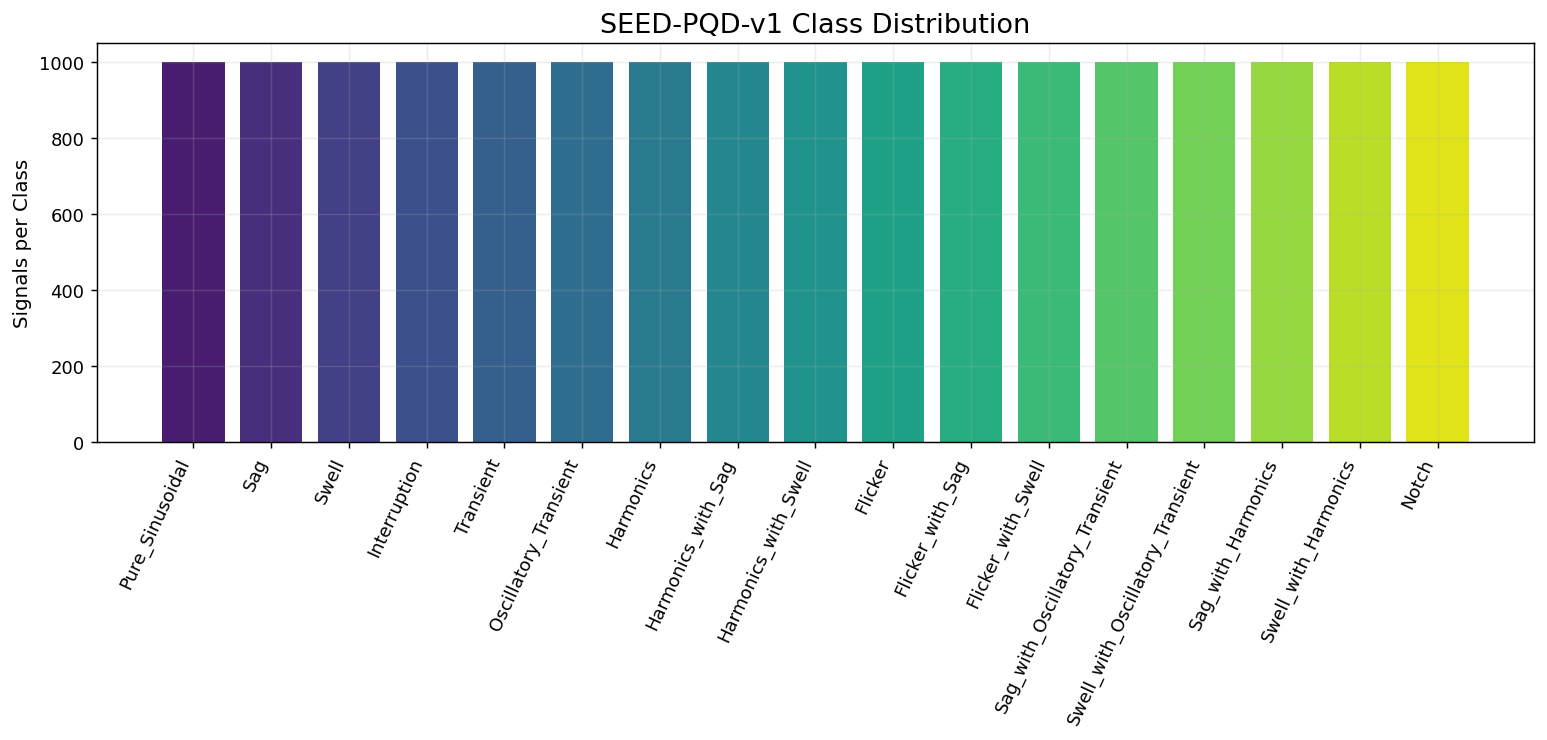

In [ ]:
CLASS_ORDER = [
    "Pure_Sinusoidal",
    "Sag",
    "Swell",
    "Interruption",
    "Transient",
    "Oscillatory_Transient",
    "Harmonics",
    "Harmonics_with_Sag",
    "Harmonics_with_Swell",
    "Flicker",
    "Flicker_with_Sag",
    "Flicker_with_Swell",
    "Sag_with_Oscillatory_Transient",
    "Swell_with_Oscillatory_Transient",
    "Sag_with_Harmonics",
    "Swell_with_Harmonics",
    "Notch",
]

pq_data = {}

for cls in CLASS_ORDER:
    path = os.path.join(DATASET_DIR, f"{cls}.csv")
    if not os.path.exists(path):
        raise FileNotFoundError(path)

    arr = pd.read_csv(path, header=None).to_numpy(dtype=float)

    if arr.shape != (1000, 100):
        raise ValueError(f"Unexpected shape for {cls}: {arr.shape}")

    pq_data[cls] = arr

shape_table = pd.DataFrame({
    "Class": CLASS_ORDER,
    "Signals": [pq_data[c].shape[0] for c in CLASS_ORDER],
    "Samples_per_Signal": [pq_data[c].shape[1] for c in CLASS_ORDER],
})

display(shape_table)

colors = VIRIDIS(np.linspace(0.08, 0.95, len(CLASS_ORDER)))

plt.figure(figsize=(12, 5.8))
plt.bar(np.arange(len(CLASS_ORDER)), shape_table["Signals"], color=colors)
plt.xticks(np.arange(len(CLASS_ORDER)), CLASS_ORDER, rotation=65, ha="right")
plt.ylabel("Signals per Class")
plt.title("SEED-PQD-v1 Class Distribution")
finish_plot("stage02_class_distribution.png")

## Stage 3 — SEED-PQD Waveform Atlas

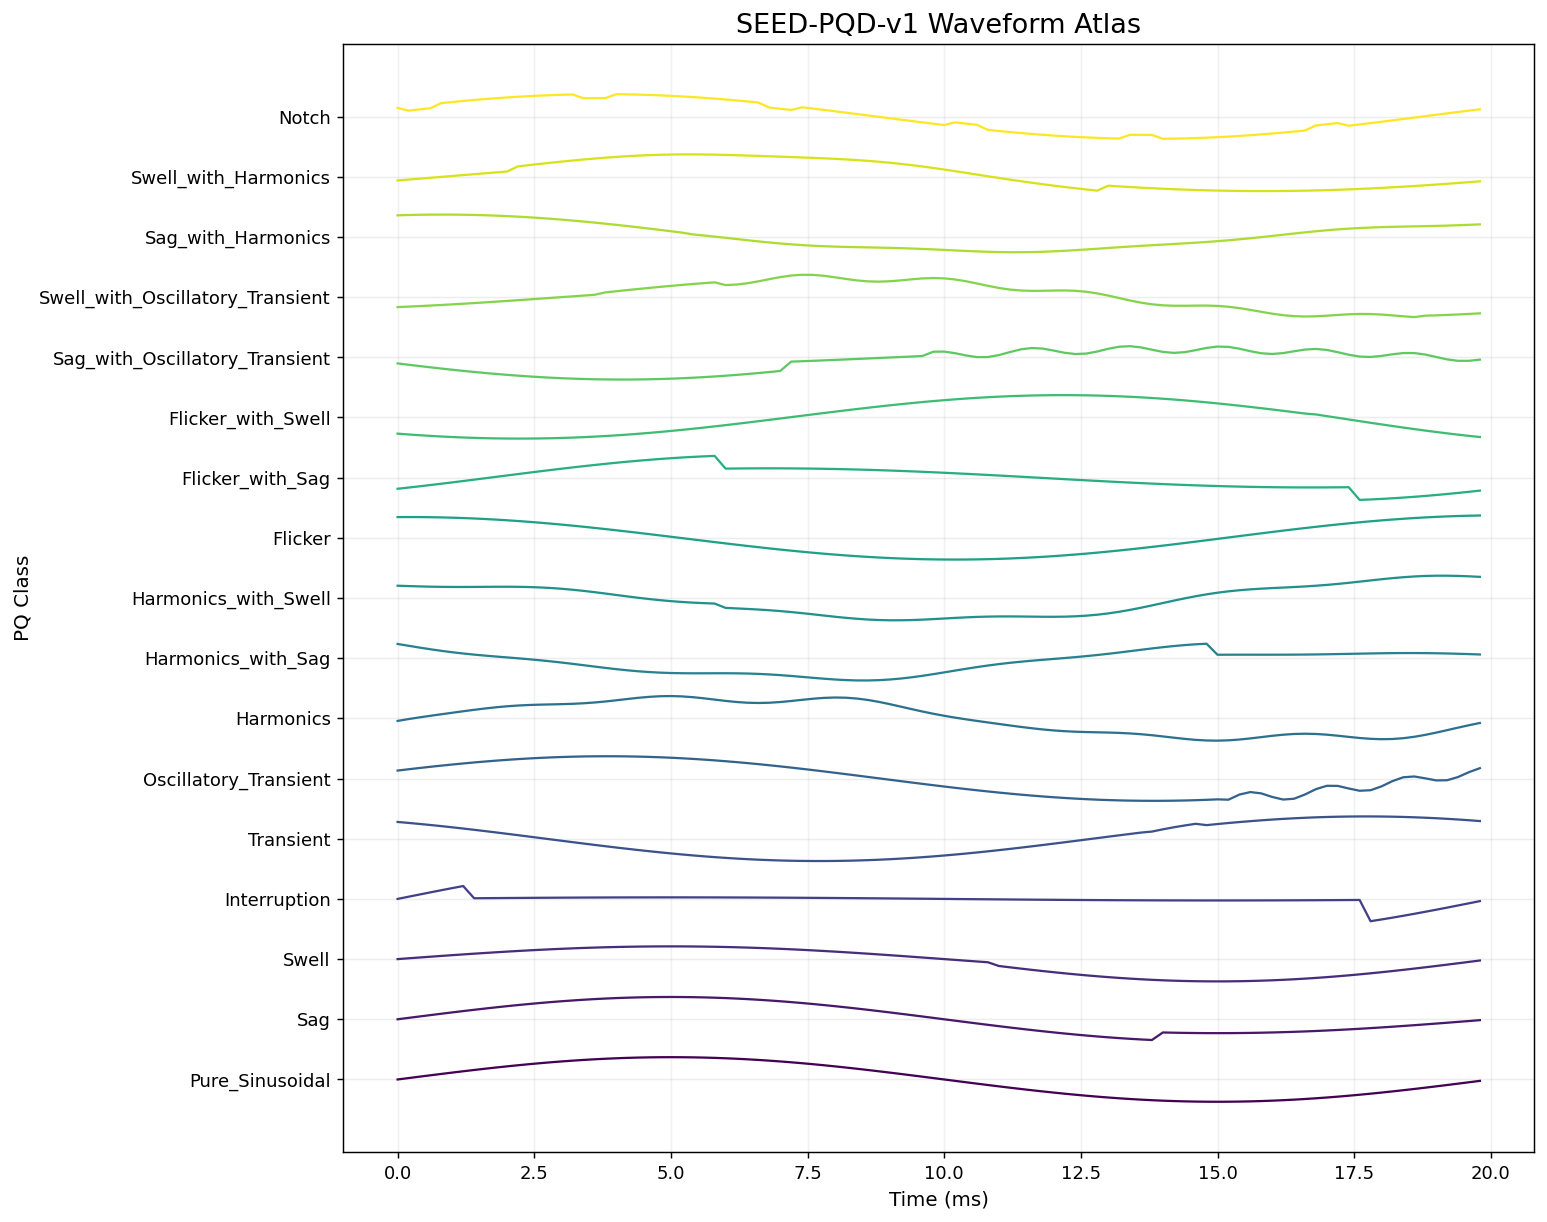

In [ ]:
FS_DATA = 5000
t_data_ms = np.arange(100) / FS_DATA * 1000

plt.figure(figsize=(12, 9.5))

offset = 2.7

for i, cls in enumerate(CLASS_ORDER):
    x = pq_data[cls][0]
    x = x / (np.max(np.abs(x)) + 1e-12)
    plt.plot(
        t_data_ms,
        x + i * offset,
        lw=1.25,
        color=VIRIDIS(i / (len(CLASS_ORDER) - 1))
    )

plt.yticks(np.arange(len(CLASS_ORDER)) * offset, CLASS_ORDER)
plt.xlabel("Time (ms)")
plt.ylabel("PQ Class")
plt.title("SEED-PQD-v1 Waveform Atlas")
plt.grid(axis="x", alpha=0.18)
finish_plot("stage03_waveform_atlas.png")

## Stage 4 — Electrical System Parameters and 27 Matrix-Converter States

,Output_A_Input,Output_B_Input,Output_C_Input
0,0,0,0
1,0,0,1
2,0,0,2
3,0,1,0
4,0,1,1
5,0,1,2
6,0,2,0
7,0,2,1
8,0,2,2
9,1,0,0


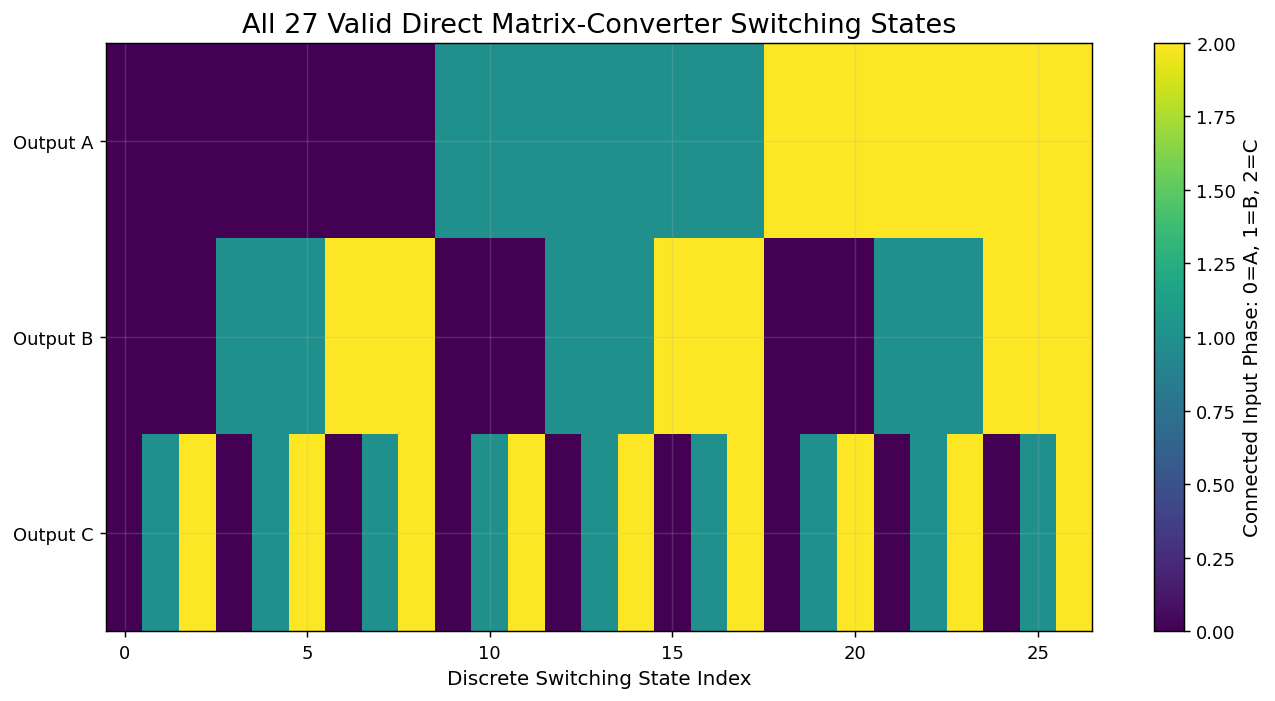

In [ ]:
FS_SIM = 20000
DT = 1 / FS_SIM
F_GRID = 50
SPC = int(FS_SIM / F_GRID)

V_LL_RMS = 415.0
V_PHASE_RMS = V_LL_RMS / np.sqrt(3)
V_PHASE_PEAK = np.sqrt(2) * V_PHASE_RMS

PV_RATED_W = 8000.0
PV_TEMP_COEFF = -0.004

I1_PEAK = 26.0
LOAD_PF_ANGLE = np.deg2rad(25)

SERIES_RATIO = 1.40
SERIES_L = 2e-3
SERIES_C = 40e-6
SERIES_R = 1.0

SHUNT_RATIO = 1.40
SHUNT_L = 6e-3
SHUNT_R = 0.15

SWITCH_STATES = np.array(
    list(itertools.product(range(3), repeat=3)),
    dtype=int
)

assert SWITCH_STATES.shape == (27, 3)

STATE_DISTANCE = np.mean(
    SWITCH_STATES[:, None, :] != SWITCH_STATES[None, :, :],
    axis=2
)

state_table = pd.DataFrame(
    SWITCH_STATES,
    columns=["Output_A_Input", "Output_B_Input", "Output_C_Input"]
)

display(state_table)

plt.figure(figsize=(10.5, 5.5))
img = plt.imshow(
    SWITCH_STATES.T,
    aspect="auto",
    cmap="viridis",
    interpolation="nearest"
)
plt.colorbar(img, label="Connected Input Phase: 0=A, 1=B, 2=C")
plt.yticks([0, 1, 2], ["Output A", "Output B", "Output C"])
plt.xlabel("Discrete Switching State Index")
plt.title("All 27 Valid Direct Matrix-Converter Switching States")
finish_plot("stage04_switching_states.png")

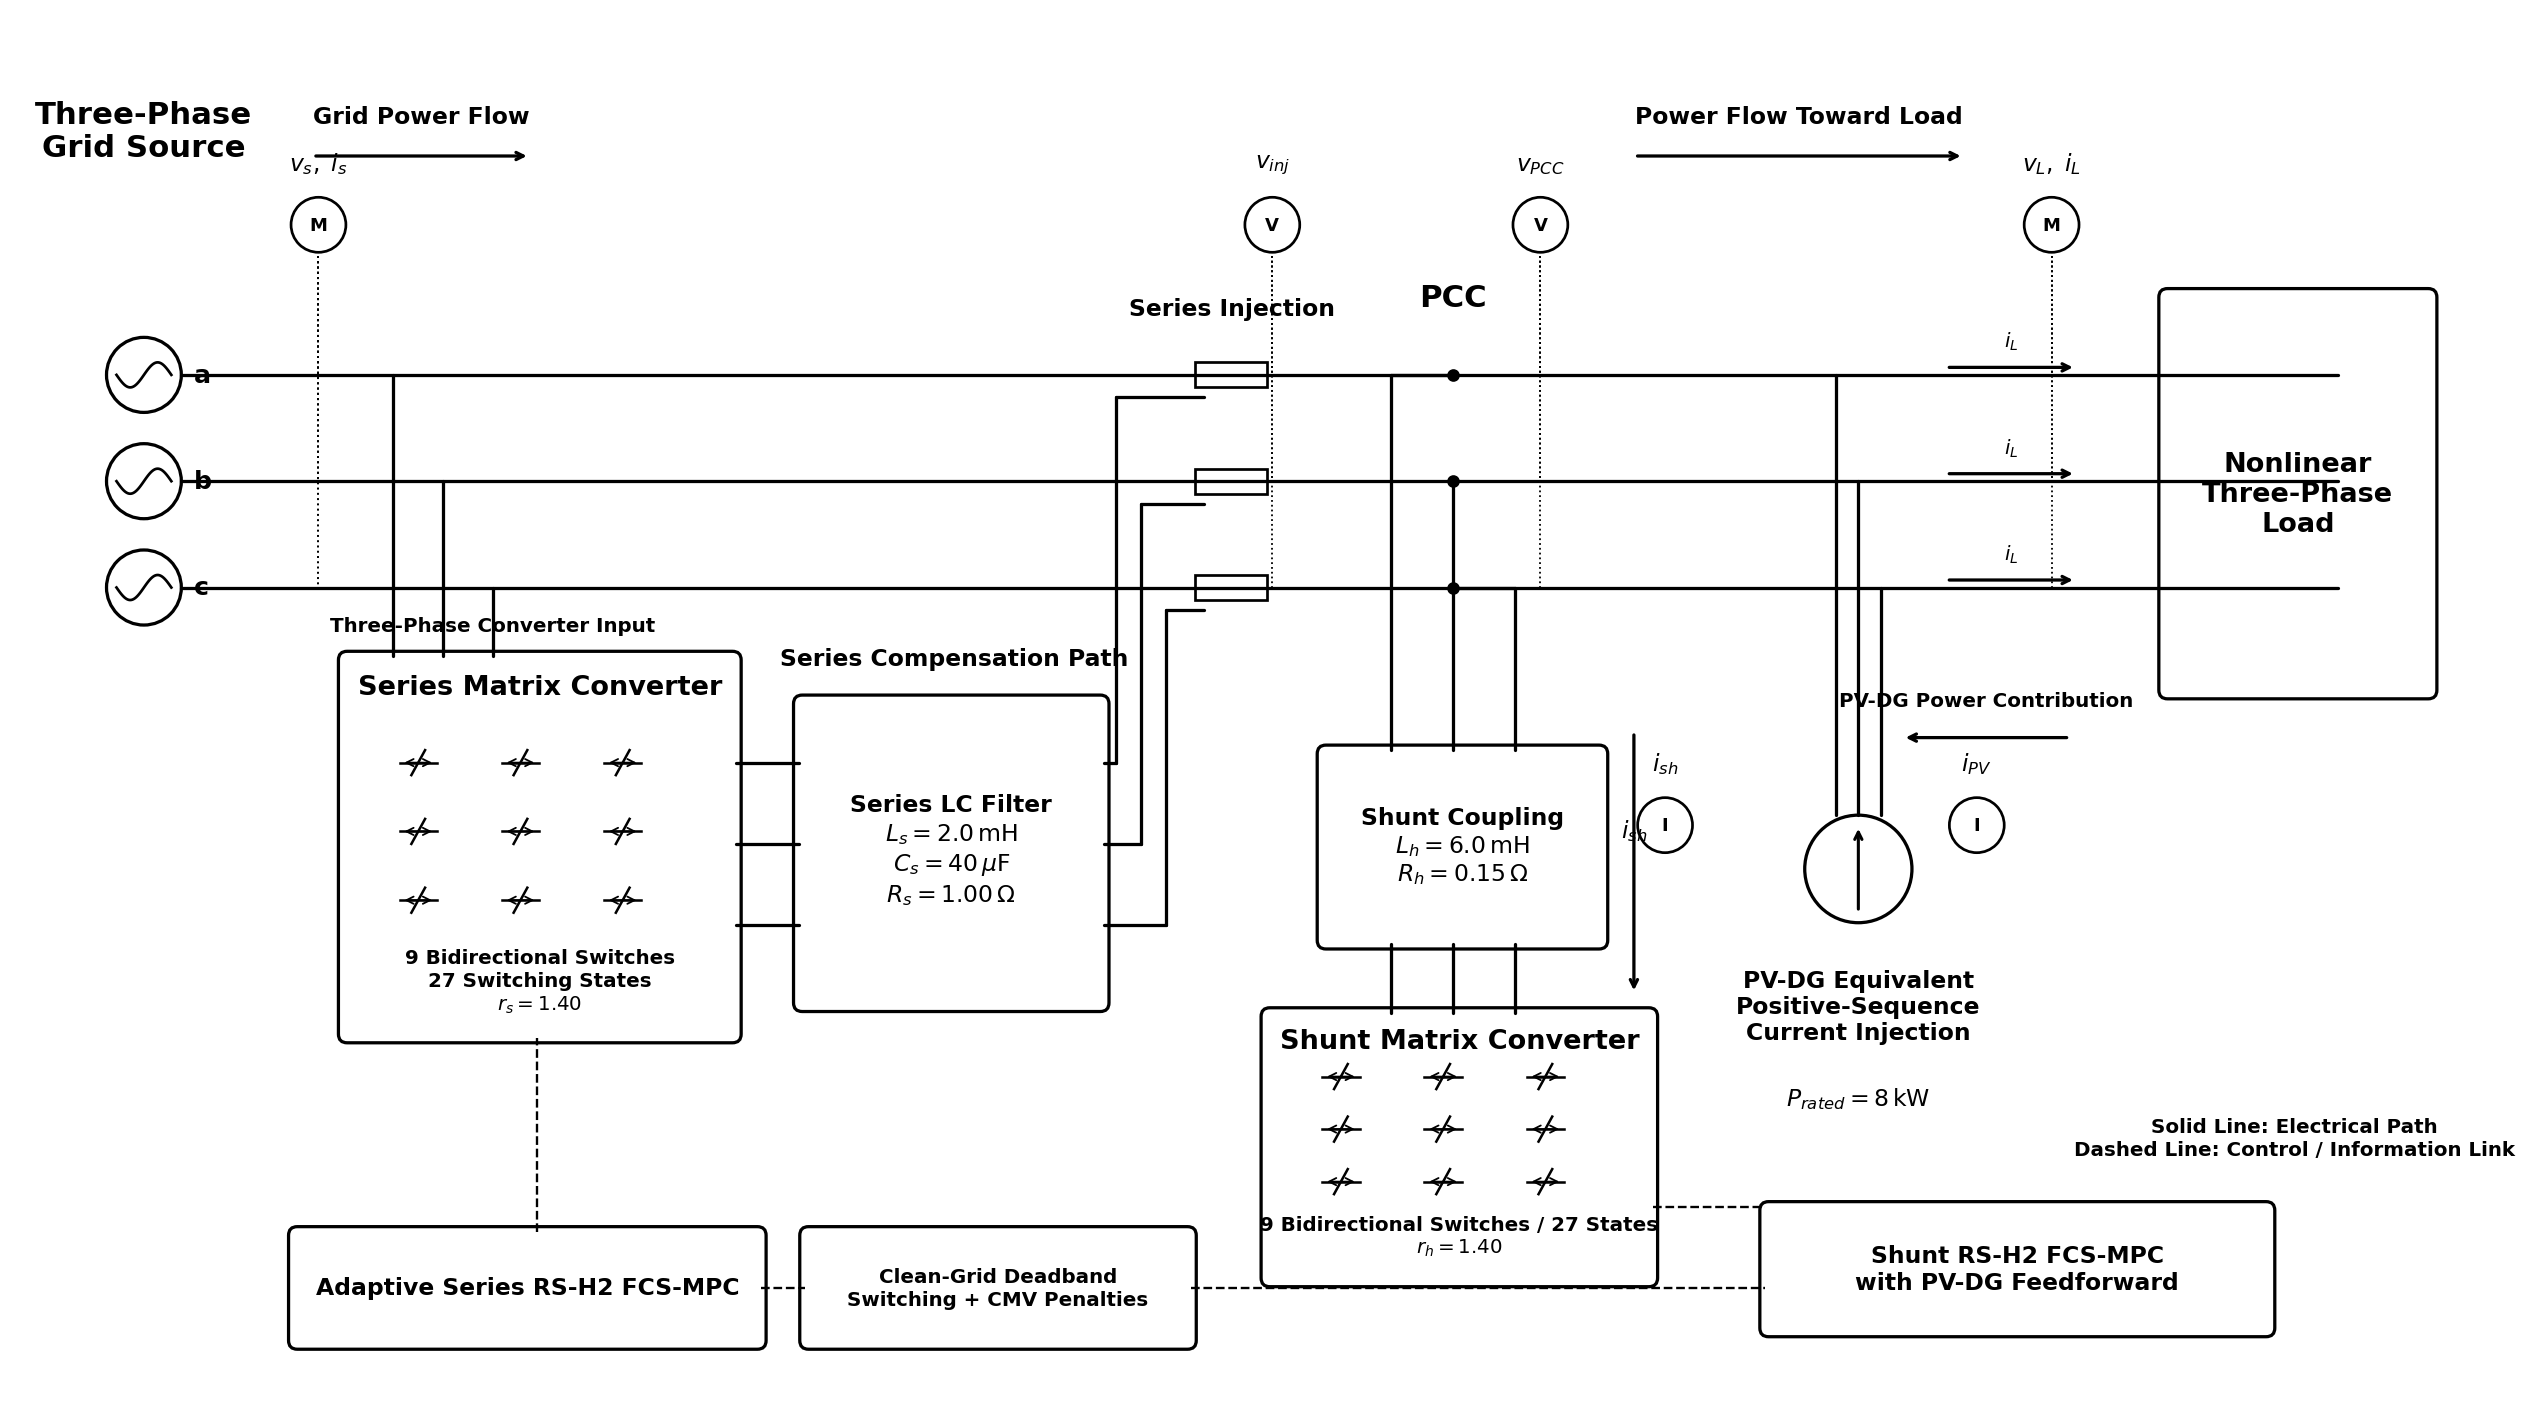

Saved schematic: /content/drive/MyDrive/dataset/SEED_PQD_v1/UPQC_Adaptive_RS_H2_FCS_Results/stage04a_matrix_converter_upqc_electrical_schematic.png


In [ ]:
from matplotlib import patches
import matplotlib.pyplot as plt
import numpy as np
import os

def draw_upqc_electrical_schematic():

    # ================================================================
    # GLOBAL FIGURE
    # ================================================================
    fig, ax = plt.subplots(figsize=(20, 11))

    ax.set_xlim(0, 20)
    ax.set_ylim(0, 11)
    ax.axis("off")

    # Global text settings
    FS_SMALL = 11
    FS_NORMAL = 13
    FS_LABEL = 14
    FS_BLOCK = 15
    FS_HEADING = 17

    FONT = {
        "fontweight": "bold"
    }

    # ================================================================
    # BASIC DRAWING FUNCTIONS
    # ================================================================
    def wire(x1, y1, x2, y2, lw=1.8, ls="-"):
        ax.plot(
            [x1, x2],
            [y1, y2],
            color="black",
            lw=lw,
            ls=ls,
            solid_capstyle="round",
            zorder=2
        )

    def box(
        x,
        y,
        w,
        h,
        label="",
        fontsize=FS_NORMAL,
        lw=1.8
    ):
        rect = patches.FancyBboxPatch(
            (x, y),
            w,
            h,
            boxstyle="round,pad=0.04,rounding_size=0.07",
            fill=False,
            edgecolor="black",
            lw=lw,
            zorder=3
        )
        ax.add_patch(rect)

        if label:
            ax.text(
                x + w / 2,
                y + h / 2,
                label,
                ha="center",
                va="center",
                fontsize=fontsize,
                fontweight="bold",
                linespacing=1.25,
                zorder=5
            )

        return rect

    def arrow(
        x1,
        y1,
        x2,
        y2,
        label=None,
        text_offset=0.22,
        fontsize=FS_SMALL
    ):
        ax.annotate(
            "",
            xy=(x2, y2),
            xytext=(x1, y1),
            arrowprops=dict(
                arrowstyle="->",
                color="black",
                lw=1.8
            ),
            zorder=4
        )

        if label:
            ax.text(
                (x1 + x2) / 2,
                (y1 + y2) / 2 + text_offset,
                label,
                ha="center",
                va="bottom",
                fontsize=fontsize,
                fontweight="bold",
                zorder=5
            )

    def measurement(
        x,
        y,
        label,
        symbol="M",
        fontsize=FS_SMALL
    ):
        ax.add_patch(
            patches.Circle(
                (x, y),
                0.22,
                fill=False,
                edgecolor="black",
                lw=1.5,
                zorder=4
            )
        )

        ax.text(
            x,
            y,
            symbol,
            ha="center",
            va="center",
            fontsize=10,
            fontweight="bold",
            zorder=5
        )

        ax.text(
            x,
            y + 0.39,
            label,
            ha="center",
            va="bottom",
            fontsize=fontsize,
            fontweight="bold",
            zorder=5
        )

    def switch_matrix(
        x0,
        y0,
        dx=0.76,
        dy=0.50
    ):
        for rr in range(3):
            for cc in range(3):

                x = x0 + cc * dx
                y = y0 + rr * dy

                ax.plot(
                    [x - 0.15, x + 0.15],
                    [y, y],
                    color="black",
                    lw=1.4,
                    zorder=4
                )

                ax.plot(
                    [x - 0.055, x + 0.055],
                    [y - 0.10, y + 0.10],
                    color="black",
                    lw=1.4,
                    zorder=4
                )

                ax.annotate(
                    "",
                    xy=(x + 0.14, y),
                    xytext=(x - 0.14, y),
                    arrowprops=dict(
                        arrowstyle="<->",
                        color="black",
                        lw=1.0
                    )
                )

    # ================================================================
    # PHASE POSITIONS
    # ================================================================
    phase_y = [8.10, 7.25, 6.40]
    phase_names = ["a", "b", "c"]

    # ================================================================
    # THREE-PHASE GRID SOURCE
    # ================================================================
    ax.text(
        1.05,
        10.05,
        "Three-Phase\nGrid Source",
        ha="center",
        va="center",
        fontsize=FS_HEADING,
        fontweight="bold",
        linespacing=1.15
    )

    for y, ph in zip(phase_y, phase_names):

        ax.add_patch(
            patches.Circle(
                (1.05, y),
                0.30,
                fill=False,
                edgecolor="black",
                lw=1.8,
                zorder=3
            )
        )

        xx = np.linspace(-np.pi, np.pi, 80)

        ax.plot(
            1.05 + 0.22 * xx / np.pi,
            y + 0.10 * np.sin(xx),
            color="black",
            lw=1.5,
            zorder=4
        )

        ax.text(
            1.45,
            y,
            ph,
            va="center",
            fontsize=FS_LABEL,
            fontweight="bold"
        )

        wire(1.35, y, 18.65, y)

    # ================================================================
    # SOURCE MEASUREMENT
    # ================================================================
    measurement(
        2.45,
        9.30,
        r"$v_s,\; i_s$",
        "M",
        FS_NORMAL
    )

    for y in phase_y:
        wire(
            2.45,
            9.05,
            2.45,
            y,
            lw=1.1,
            ls=":"
        )

    arrow(
        2.4,
        9.85,
        4.15,
        9.85,
        "Grid Power Flow",
        fontsize=FS_NORMAL
    )

    # ================================================================
    # SERIES MATRIX CONVERTER
    # ================================================================
    box(
        2.65,
        2.80,
        3.15,
        3.05
    )

    ax.text(
        4.225,
        5.55,
        "Series Matrix Converter",
        ha="center",
        fontsize=FS_BLOCK,
        fontweight="bold"
    )

    switch_matrix(
        3.25,
        3.90,
        dx=0.82,
        dy=0.55
    )

    ax.text(
        4.225,
        3.25,
        "9 Bidirectional Switches\n"
        "27 Switching States\n"
        rf"$r_s={SERIES_RATIO:.2f}$",
        ha="center",
        va="center",
        fontsize=FS_SMALL,
        fontweight="bold",
        linespacing=1.25
    )

    # Converter input connections
    input_x = [3.05, 3.45, 3.85]

    for x, y in zip(input_x, phase_y):
        wire(
            x,
            y,
            x,
            5.85
        )

    ax.text(
        3.85,
        6.05,
        "Three-Phase Converter Input",
        ha="center",
        fontsize=FS_SMALL,
        fontweight="bold"
    )

    # ================================================================
    # SERIES LC FILTER
    # ================================================================
    box(
        6.30,
        3.05,
        2.45,
        2.45
    )

    ax.text(
        7.525,
        4.30,
        "Series LC Filter\n"
        + rf"$L_s={SERIES_L*1e3:.1f}\,\mathrm{{mH}}$"
        + "\n"
        + rf"$C_s={SERIES_C*1e6:.0f}\,\mu\mathrm{{F}}$"
        + "\n"
        + rf"$R_s={SERIES_R:.2f}\,\Omega$",
        ha="center",
        va="center",
        fontsize=FS_NORMAL,
        fontweight="bold",
        linespacing=1.25
    )

    # Series converter output to filter
    filter_phase_y = [5.00, 4.35, 3.70]

    for y in filter_phase_y:
        wire(
            5.80,
            y,
            6.30,
            y
        )

    # ================================================================
    # SERIES INJECTION CONNECTION
    # ================================================================
    injection_x = [8.85, 9.05, 9.25]

    for y_filter, y_phase, x_rise in zip(
        filter_phase_y,
        phase_y,
        injection_x
    ):
        wire(
            8.75,
            y_filter,
            x_rise,
            y_filter
        )

        wire(
            x_rise,
            y_filter,
            x_rise,
            y_phase - 0.18
        )

        wire(
            x_rise,
            y_phase - 0.18,
            9.55,
            y_phase - 0.18
        )

    ax.text(
        7.55,
        5.78,
        "Series Compensation Path",
        ha="center",
        fontsize=FS_NORMAL,
        fontweight="bold"
    )

    # Explicit series injection markers
    for y in phase_y:
        ax.add_patch(
            patches.Rectangle(
                (9.48, y - 0.10),
                0.58,
                0.20,
                fill=False,
                edgecolor="black",
                lw=1.5,
                zorder=4
            )
        )

    ax.text(
        9.78,
        8.58,
        "Series Injection",
        ha="center",
        fontsize=FS_NORMAL,
        fontweight="bold"
    )

    measurement(
        10.10,
        9.30,
        r"$v_{inj}$",
        "V",
        FS_NORMAL
    )

    for y in phase_y:
        wire(
            10.10,
            9.05,
            10.10,
            y,
            lw=1.0,
            ls=":"
        )

    # ================================================================
    # PCC
    # ================================================================
    x_pcc = 11.55

    for y in phase_y:
        ax.plot(
            x_pcc,
            y,
            "o",
            color="black",
            ms=6,
            zorder=5
        )

    ax.text(
        x_pcc,
        8.65,
        "PCC",
        ha="center",
        fontsize=FS_HEADING,
        fontweight="bold"
    )

    measurement(
        12.25,
        9.30,
        r"$v_{PCC}$",
        "V",
        FS_NORMAL
    )

    for y in phase_y:
        wire(
            12.25,
            9.05,
            12.25,
            y,
            lw=1.0,
            ls=":"
        )

    arrow(
        13.0,
        9.85,
        15.65,
        9.85,
        "Power Flow Toward Load",
        fontsize=FS_NORMAL
    )

    # ================================================================
    # NONLINEAR LOAD
    # ================================================================
    box(
        17.25,
        5.55,
        2.15,
        3.20
    )

    ax.text(
        18.325,
        7.15,
        "Nonlinear\nThree-Phase\nLoad",
        ha="center",
        va="center",
        fontsize=FS_BLOCK,
        fontweight="bold",
        linespacing=1.20
    )

    measurement(
        16.35,
        9.30,
        r"$v_L,\; i_L$",
        "M",
        FS_NORMAL
    )

    for y in phase_y:
        wire(
            16.35,
            9.05,
            16.35,
            y,
            lw=1.0,
            ls=":"
        )

        arrow(
            15.50,
            y + 0.06,
            16.55,
            y + 0.06,
            r"$i_L$",
            text_offset=0.12,
            fontsize=FS_SMALL
        )

    # ================================================================
    # SHUNT COUPLING BRANCH
    # ================================================================
    box(
        10.50,
        3.55,
        2.25,
        1.55
    )

    ax.text(
        11.625,
        4.33,
        "Shunt Coupling\n"
        + rf"$L_h={SHUNT_L*1e3:.1f}\,\mathrm{{mH}}$"
        + "\n"
        + rf"$R_h={SHUNT_R:.2f}\,\Omega$",
        ha="center",
        va="center",
        fontsize=FS_NORMAL,
        fontweight="bold",
        linespacing=1.20
    )

    shunt_x = [11.05, 11.55, 12.05]

    for x, y_phase in zip(
        shunt_x,
        phase_y
    ):
        wire(
            x_pcc,
            y_phase,
            x,
            y_phase
        )

        wire(
            x,
            y_phase,
            x,
            5.10
        )

        wire(
            x,
            3.55,
            x,
            3.00
        )

    measurement(
        13.25,
        4.50,
        r"$i_{sh}$",
        "I",
        FS_NORMAL
    )

    arrow(
        13.00,
        5.25,
        13.00,
        3.15,
        r"$i_{sh}$",
        text_offset=0.16,
        fontsize=FS_NORMAL
    )

    # ================================================================
    # SHUNT MATRIX CONVERTER
    # ================================================================
    box(
        10.05,
        0.85,
        3.10,
        2.15
    )

    ax.text(
        11.60,
        2.72,
        "Shunt Matrix Converter",
        ha="center",
        fontsize=FS_BLOCK,
        fontweight="bold"
    )

    switch_matrix(
        10.65,
        1.65,
        dx=0.82,
        dy=0.42
    )

    ax.text(
        11.60,
        1.08,
        "9 Bidirectional Switches / 27 States\n"
        + rf"$r_h={SHUNT_RATIO:.2f}$",
        ha="center",
        fontsize=FS_SMALL,
        fontweight="bold",
        linespacing=1.20
    )

    # ================================================================
    # PV-DG EQUIVALENT CURRENT INJECTION
    # ================================================================
    x_pv = 14.80

    ax.add_patch(
        patches.Circle(
            (x_pv, 4.15),
            0.43,
            fill=False,
            edgecolor="black",
            lw=1.8,
            zorder=4
        )
    )

    ax.annotate(
        "",
        xy=(x_pv, 4.50),
        xytext=(x_pv, 3.80),
        arrowprops=dict(
            arrowstyle="->",
            color="black",
            lw=1.7
        )
    )

    pv_x = [
        x_pv - 0.18,
        x_pv,
        x_pv + 0.18
    ]

    for x, y_phase in zip(
        pv_x,
        phase_y
    ):
        wire(
            x,
            4.58,
            x,
            y_phase
        )

    measurement(
        15.75,
        4.50,
        r"$i_{PV}$",
        "I",
        FS_NORMAL
    )

    arrow(
        16.50,
        5.20,
        15.15,
        5.20,
        "PV-DG Power Contribution",
        fontsize=FS_SMALL
    )

    ax.text(
        14.80,
        3.35,
        "PV-DG Equivalent\n"
        "Positive-Sequence\n"
        "Current Injection",
        ha="center",
        va="top",
        fontsize=FS_NORMAL,
        fontweight="bold",
        linespacing=1.18
    )

    ax.text(
        14.80,
        2.42,
        rf"$P_{{rated}}={PV_RATED_W/1000:.0f}\,\mathrm{{kW}}$",
        ha="center",
        va="top",
        fontsize=FS_NORMAL,
        fontweight="bold"
    )

    # ================================================================
    # CONTROL ANNOTATIONS
    # ================================================================

    # Series controller
    box(
        2.25,
        0.35,
        3.75,
        0.90,
        "Adaptive Series RS-H2 FCS-MPC",
        FS_NORMAL
    )

    wire(
        4.20,
        1.25,
        4.20,
        2.80,
        lw=1.3,
        ls="--"
    )

    # Shared penalties
    box(
        6.35,
        0.35,
        3.10,
        0.90,
        "Clean-Grid Deadband\n"
        "Switching + CMV Penalties",
        FS_SMALL
    )

    wire(
        6.00,
        0.80,
        6.35,
        0.80,
        lw=1.3,
        ls="--"
    )

    # Shunt controller
    box(
        14.05,
        0.45,
        4.05,
        1.00,
        "Shunt RS-H2 FCS-MPC\n"
        "with PV-DG Feedforward",
        FS_NORMAL
    )

    wire(
        13.15,
        1.45,
        14.05,
        1.45,
        lw=1.3,
        ls="--"
    )

    wire(
        9.45,
        0.80,
        14.05,
        0.80,
        lw=1.3,
        ls="--"
    )

    # ================================================================
    # LEGEND
    # ================================================================
    ax.text(
        18.30,
        2.00,
        "Solid Line: Electrical Path\n"
        "Dashed Line: Control / Information Link",
        ha="center",
        va="center",
        fontsize=FS_SMALL,
        fontweight="bold",
        linespacing=1.25
    )

    # ================================================================
    # FINAL OUTPUT
    # ================================================================
    plt.tight_layout(pad=1.5)

    schematic_path = os.path.join(
        RESULTS_DIR,
        "stage04a_matrix_converter_upqc_electrical_schematic.png"
    )

    plt.savefig(
        schematic_path,
        dpi=300,
        bbox_inches="tight",
        pad_inches=0.18
    )

    plt.show()

    print("Saved schematic:", schematic_path)

    return schematic_path


SCHEMATIC_PATH = draw_upqc_electrical_schematic()

## Stage 5 — Signal Processing, Three-Phase Synthesis, and Synchronization

In [ ]:
def fractional_shift(x, shift_samples):
    x = np.asarray(x, dtype=float)
    n = len(x)
    k = fftfreq(n)
    return ifft(
        fft(x) * np.exp(-2j * np.pi * k * shift_samples)
    ).real


def align_fundamental(x, target_phase=-np.pi / 2):
    x = np.asarray(x, dtype=float)
    phase = np.angle(fft(x)[1])

    diff = (phase - target_phase + np.pi) % (2 * np.pi) - np.pi
    shift = diff * len(x) / (2 * np.pi)

    return fractional_shift(x, shift)


def three_phase_positive_sequence(single_cycle):
    xa = resample(
        np.asarray(single_cycle, dtype=float),
        SPC
    ).real

    analytic = hilbert(xa)

    xb = np.real(
        analytic * np.exp(-1j * 2 * np.pi / 3)
    )

    xc = np.real(
        analytic * np.exp(1j * 2 * np.pi / 3)
    )

    return V_PHASE_PEAK * np.column_stack([xa, xb, xc])


def clarke(vabc):
    va, vb, vc = vabc[:, 0], vabc[:, 1], vabc[:, 2]

    alpha = (2 / 3) * (
        va - 0.5 * vb - 0.5 * vc
    )

    beta = (2 / 3) * (
        np.sqrt(3) / 2
    ) * (vb - vc)

    return alpha, beta


def lowpass(x, tau, fs=None, initial=None):
    if fs is None:
        fs = FS_SIM

    x = np.asarray(x)

    y = np.empty_like(
        x,
        dtype=np.result_type(x, float)
    )

    a = np.exp(-1 / (fs * tau))

    y[0] = x[0] if initial is None else initial

    for k in range(1, len(x)):
        y[k] = a * y[k - 1] + (1 - a) * x[k]

    return y


def robust_positive_sequence_sync(
    vabc,
    fs=None,
    f0=F_GRID,
    tau=0.012
):
    if fs is None:
        fs = FS_SIM

    alpha, beta = clarke(vabc)

    tt = np.arange(len(vabc)) / fs

    z = alpha + 1j * beta

    baseband = z * np.exp(
        -1j * 2 * np.pi * f0 * tt
    )

    bb_lp = lowpass(
        baseband,
        tau=tau,
        fs=fs
    )

    correction = np.unwrap(
        np.angle(bb_lp)
    )

    theta = (
        2 * np.pi * f0 * tt
        + correction
        + np.pi / 2
    )

    freq = np.gradient(theta) * fs / (2 * np.pi)

    freq = lowpass(
        freq,
        tau=0.020,
        fs=fs,
        initial=f0
    )

    return theta, freq


def make_vref(theta):
    return V_PHASE_PEAK * np.column_stack([
        np.sin(theta),
        np.sin(theta - 2 * np.pi / 3),
        np.sin(theta + 2 * np.pi / 3),
    ])

## Stage 6 — Composite SEED-PQD Grid Disturbance Sequence

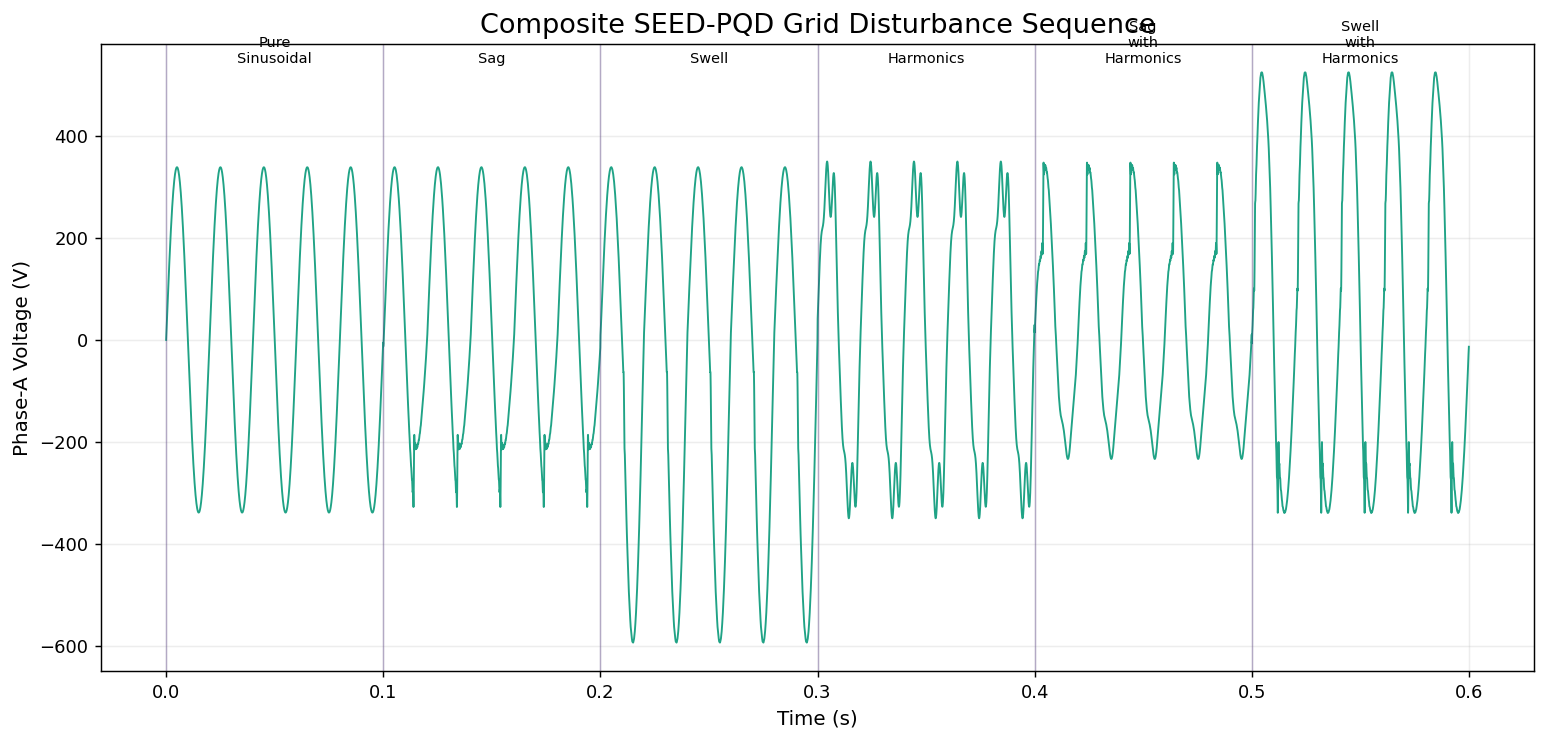

In [ ]:
MAIN_SCENARIOS = [
    "Pure_Sinusoidal",
    "Sag",
    "Swell",
    "Harmonics",
    "Sag_with_Harmonics",
    "Swell_with_Harmonics",
]

CYCLES_PER_SCENARIO = 5

chunks = []
scenario_bounds = {}
cursor = 0

for cls in MAIN_SCENARIOS:
    x = align_fundamental(
        pq_data[cls][0]
    )

    one_cycle = three_phase_positive_sequence(x)

    block = np.tile(
        one_cycle,
        (CYCLES_PER_SCENARIO, 1)
    )

    scenario_bounds[cls] = (
        cursor,
        cursor + len(block)
    )

    cursor += len(block)
    chunks.append(block)

v_source = np.vstack(chunks)
t = np.arange(len(v_source)) / FS_SIM

theta_sync, freq_sync = robust_positive_sequence_sync(v_source)
v_reference = make_vref(theta_sync)

plt.figure(figsize=(12, 5.8))
plt.plot(
    t,
    v_source[:, 0],
    color=VIRIDIS(0.58),
    lw=1.05
)

for cls, (a, b) in scenario_bounds.items():
    plt.axvline(
        t[a],
        color=VIRIDIS(0.12),
        alpha=0.35,
        lw=0.8
    )

    plt.text(
        (t[a] + t[b - 1]) / 2,
        np.max(v_source[:, 0]) * 1.035,
        cls.replace("_", "\n"),
        ha="center",
        fontsize=8
    )

plt.xlabel("Time (s)")
plt.ylabel("Phase-A Voltage (V)")
plt.title("Composite SEED-PQD Grid Disturbance Sequence")
finish_plot("stage06_composite_disturbance.png")

## Stage 7 — Robust Positive-Sequence Frequency Tracking

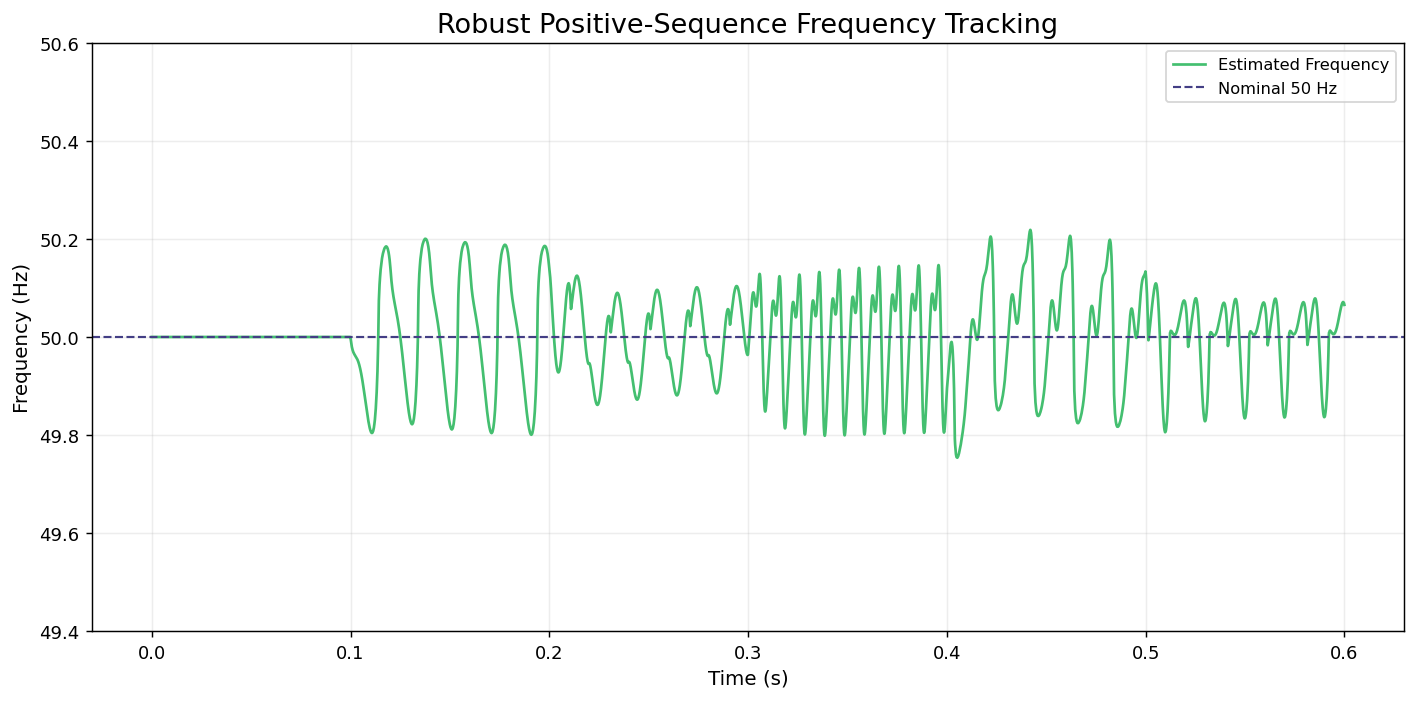

In [ ]:
plt.figure(figsize=(11, 5.5))

plt.plot(
    t,
    freq_sync,
    color=VIRIDIS(0.70),
    lw=1.5,
    label="Estimated Frequency"
)

plt.axhline(
    50,
    color=VIRIDIS(0.18),
    linestyle="--",
    lw=1.2,
    label="Nominal 50 Hz"
)

plt.ylim(49.4, 50.6)
plt.xlabel("Time (s)")
plt.ylabel("Frequency (Hz)")
plt.title("Robust Positive-Sequence Frequency Tracking")
plt.legend()
finish_plot("stage07_frequency_tracking.png")

## Stage 8 — PV-DG Irradiance and Power Model

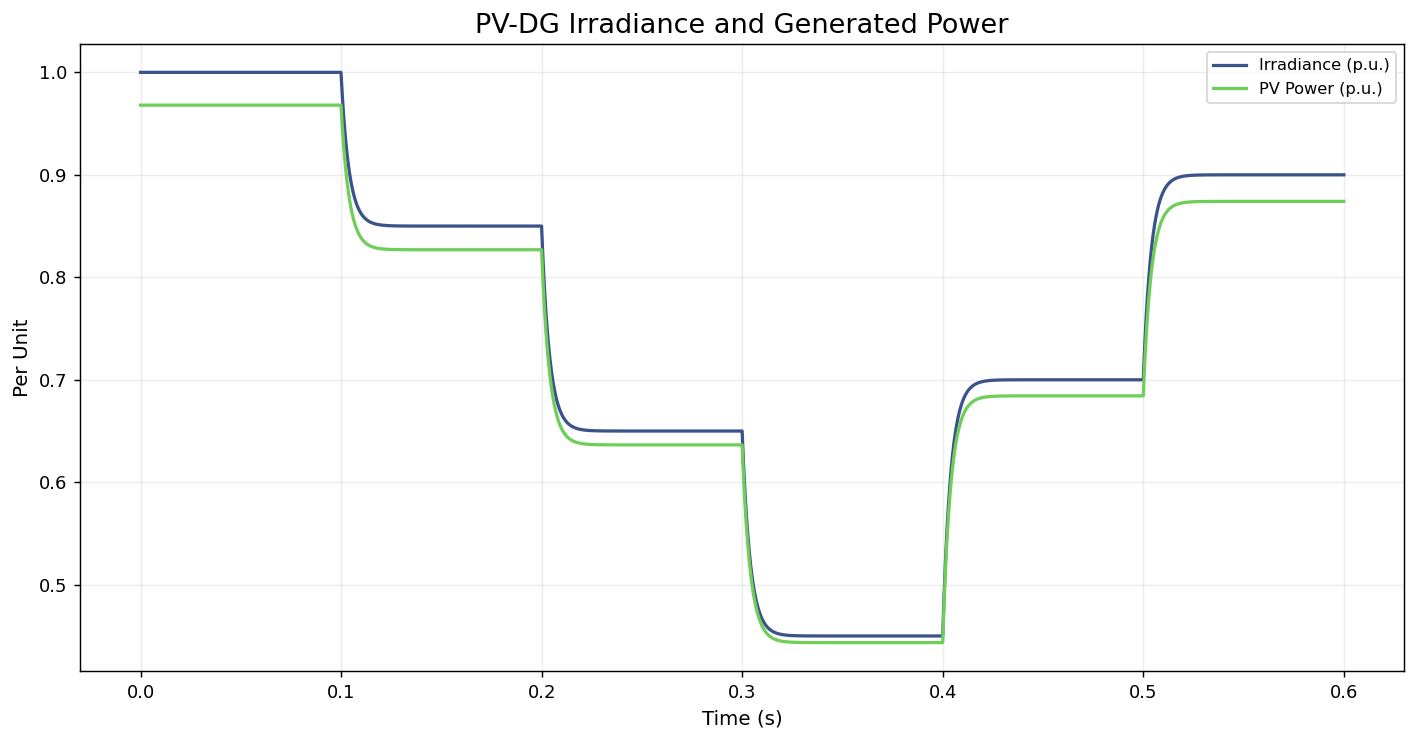

In [ ]:
irradiance_levels = [
    1000,
    850,
    650,
    450,
    700,
    900,
]

irradiance = np.zeros_like(t)

for level, cls in zip(
    irradiance_levels,
    MAIN_SCENARIOS
):
    a, b = scenario_bounds[cls]
    irradiance[a:b] = level

irradiance = lowpass(
    irradiance,
    tau=0.004,
    initial=irradiance[0]
)

temperature = 25 + 8 * (
    irradiance / 1000
)

pv_power = (
    PV_RATED_W
    * (irradiance / 1000)
    * (
        1
        + PV_TEMP_COEFF
        * (temperature - 25)
    )
)

plt.figure()

plt.plot(
    t,
    irradiance / 1000,
    color=VIRIDIS(0.25),
    lw=1.8,
    label="Irradiance (p.u.)"
)

plt.plot(
    t,
    pv_power / PV_RATED_W,
    color=VIRIDIS(0.78),
    lw=1.8,
    label="PV Power (p.u.)"
)

plt.xlabel("Time (s)")
plt.ylabel("Per Unit")
plt.title("PV-DG Irradiance and Generated Power")
plt.legend()
finish_plot("stage08_pv_dg.png")

## Stage 9 — Nonlinear Three-Phase Load

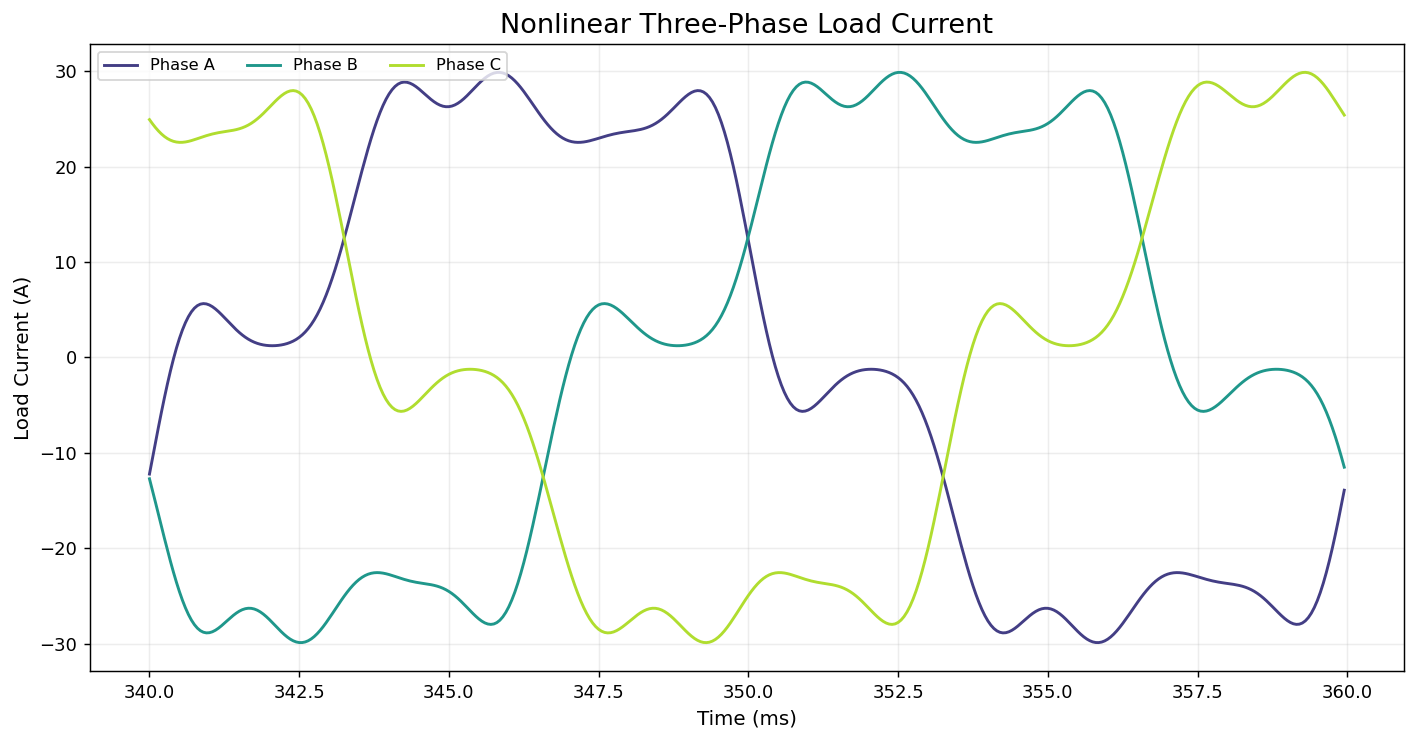

In [ ]:
load_scale = np.ones_like(t)

load_scale[
    scenario_bounds["Swell"][0]:
    scenario_bounds["Harmonics"][1]
] = 1.10

load_scale[
    scenario_bounds["Sag_with_Harmonics"][0]:
    scenario_bounds["Sag_with_Harmonics"][1]
] = 1.20

load_scale[
    scenario_bounds["Swell_with_Harmonics"][0]:
    scenario_bounds["Swell_with_Harmonics"][1]
] = 0.90

phase_offsets = np.array([
    0,
    -2 * np.pi / 3,
    2 * np.pi / 3
])

i_load = np.zeros(
    (len(t), 3)
)

for p, off in enumerate(phase_offsets):
    th = theta_sync + off

    i_load[:, p] = load_scale * (
        I1_PEAK
        * np.sin(th - LOAD_PF_ANGLE)

        + 0.22 * I1_PEAK
        * np.sin(5 * th + 0.30)

        + 0.14 * I1_PEAK
        * np.sin(7 * th - 0.20)

        + 0.06 * I1_PEAK
        * np.sin(11 * th + 0.10)
    )

a, b = scenario_bounds["Harmonics"]

sl = slice(
    a + 2 * SPC,
    a + 3 * SPC
)

colors = VIRIDIS(
    np.linspace(0.18, 0.88, 3)
)

plt.figure()

for p, col in enumerate(colors):
    plt.plot(
        t[sl] * 1000,
        i_load[sl, p],
        color=col,
        lw=1.6,
        label=f"Phase {chr(65 + p)}"
    )

plt.xlabel("Time (ms)")
plt.ylabel("Load Current (A)")
plt.title("Nonlinear Three-Phase Load Current")
plt.legend(ncol=3)
finish_plot("stage09_nonlinear_load.png")

## Stage 10 — Matrix-Converter Candidate Voltage Set

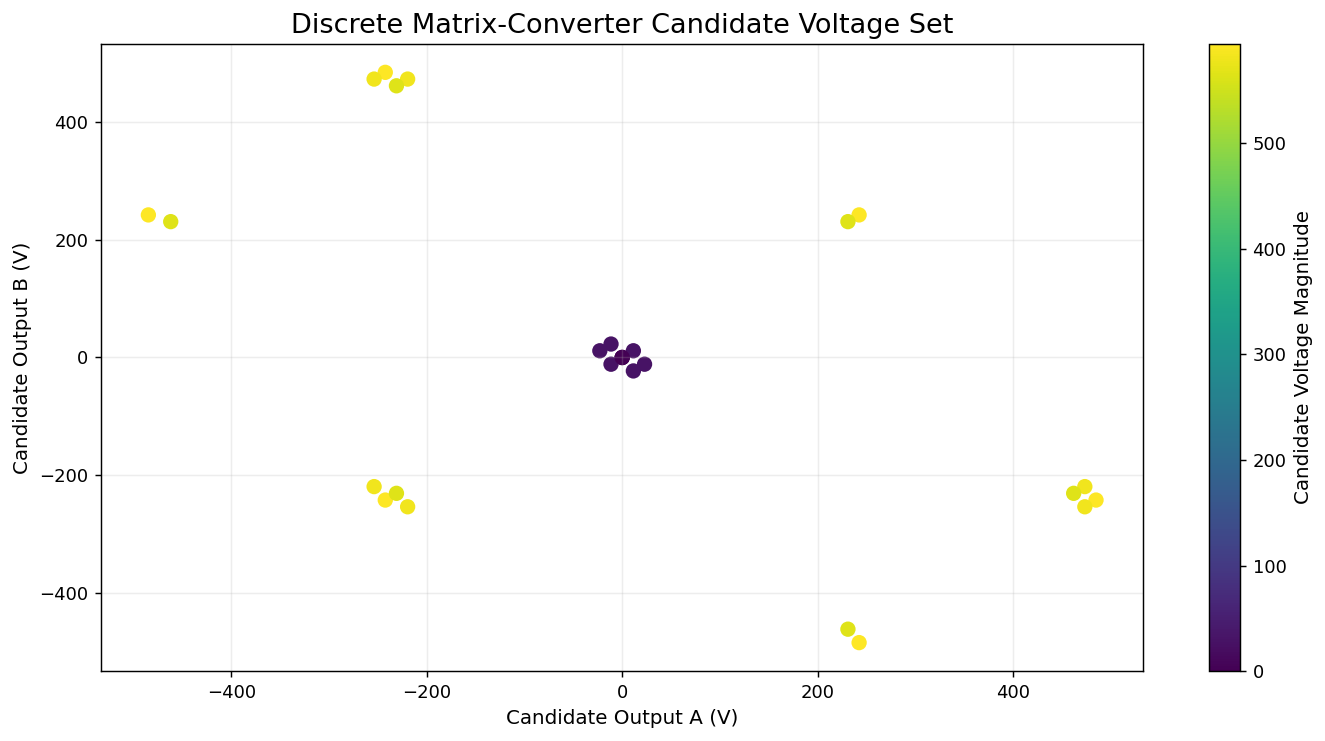

In [ ]:
def matrix_candidates(vin, ratio):
    raw = vin[SWITCH_STATES]

    common_mode = raw.mean(axis=1)

    zero_sequence_removed = (
        raw
        - common_mode[:, None]
    )

    vout = (
        ratio
        * zero_sequence_removed
    )

    return vout, common_mode


def switching_distance(prev_state):
    return np.mean(
        SWITCH_STATES != prev_state,
        axis=1
    )


k = (
    scenario_bounds["Sag"][0]
    + SPC // 4
)

cand, cm = matrix_candidates(
    v_source[k],
    SERIES_RATIO
)

mag = np.linalg.norm(
    cand,
    axis=1
)

plt.figure()

plt.scatter(
    cand[:, 0],
    cand[:, 1],
    c=mag,
    cmap="viridis",
    s=72,
    edgecolor="none"
)

plt.colorbar(
    label="Candidate Voltage Magnitude"
)

plt.xlabel("Candidate Output A (V)")
plt.ylabel("Candidate Output B (V)")
plt.title("Discrete Matrix-Converter Candidate Voltage Set")
finish_plot("stage10_candidate_voltage_set.png")

## Stage 11 — Proposed Adaptive Reduced-Set Horizon-2 FCS-MPC Series Controller with Clean-Grid Deadband

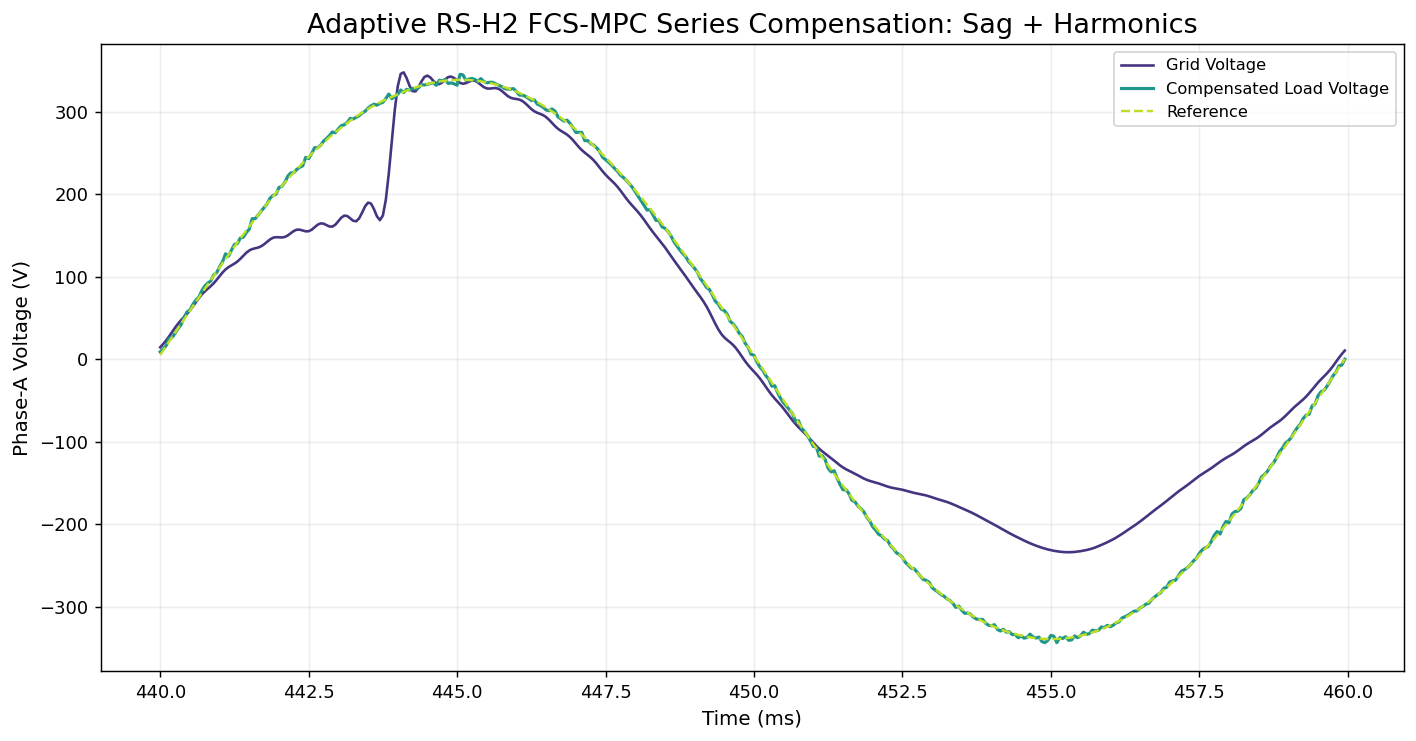

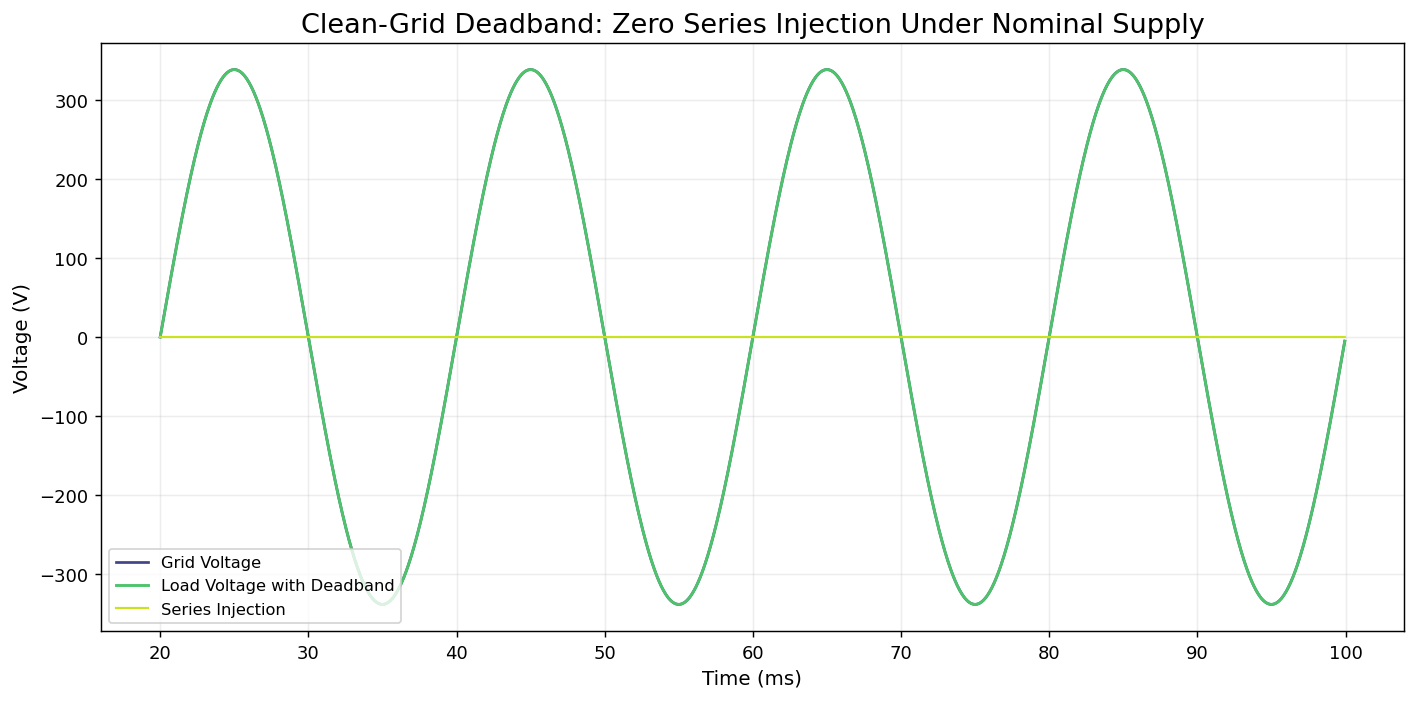

,Metric,Value
0,Deadband activation within clean segment (%),100.0
1,Series injected RMS during clean segment (V),0.0
2,Grid voltage THD during clean segment (%),0.0
3,Load voltage THD during clean segment (%),0.0


In [ ]:
SERIES_GAMMA = 0.15
SERIES_TOP_K = 6
SERIES_LAMBDA_SW = 5e-5
SERIES_LAMBDA_CMV = 2e-4
SERIES_AMP_K = 0.035
SERIES_AMP_TAU = 0.010

# Clean-grid bypass/deadband:
# When the source already matches the positive-sequence sinusoidal reference,
# the series compensator is held at a zero-output switching state.
CLEAN_GRID_DEADBAND_PU = 0.0025
CLEAN_GRID_DEADBAND_TAU = 0.001
BYPASS_STATE_IDX = 0


def clean_grid_deadband_mask(
    vs,
    vr,
    fs=None,
    threshold_pu=CLEAN_GRID_DEADBAND_PU,
    tau=CLEAN_GRID_DEADBAND_TAU,
):
    if fs is None:
        fs = FS_SIM

    normalized_mismatch = (
        np.linalg.norm(vs - vr, axis=1)
        / (np.sqrt(1.5) * V_PHASE_PEAK + 1e-12)
    )

    filtered_mismatch = lowpass(
        normalized_mismatch,
        tau=tau,
        fs=fs,
        initial=normalized_mismatch[0],
    )

    return filtered_mismatch < threshold_pu




def run_series_proposed(
    vs,
    vr,
    fs=None,
    ratio=SERIES_RATIO,
    L=SERIES_L,
    C=SERIES_C,
    R=SERIES_R,
    gamma=SERIES_GAMMA,
    top_k=SERIES_TOP_K,
    lambda_sw=SERIES_LAMBDA_SW,
    lambda_cm=SERIES_LAMBDA_CMV,
    amp_k=SERIES_AMP_K,
    amp_tau=SERIES_AMP_TAU,
):
    if fs is None:
        fs = FS_SIM

    dt = 1 / fs
    n = len(vs)

    vc = np.zeros((n, 3))
    i_f = np.zeros((n, 3))
    idx = np.zeros(n, dtype=int)

    prev_idx = 0

    bypass_mask = clean_grid_deadband_mask(
        vs,
        vr,
        fs=fs,
    )

    amp_est = np.ones(3) * V_PHASE_PEAK
    amp_alpha = np.exp(-dt / amp_tau)

    for k in range(1, n):
        if bypass_mask[k]:
            vc[k] = 0.0
            i_f[k] = 0.0
            idx[k] = BYPASS_STATE_IDX
            prev_idx = BYPASS_STATE_IDX
            amp_est[:] = V_PHASE_PEAK
            continue

        unit_prev = (
            vr[k - 1]
            / V_PHASE_PEAK
        )

        vload_prev = (
            vs[k - 1]
            + vc[k - 1]
        )

        amp_inst = (
            2
            * vload_prev
            * unit_prev
        )

        amp_est = (
            amp_alpha * amp_est
            + (1 - amp_alpha)
            * amp_inst
        )

        amp_correction = np.clip(
            amp_k
            * (
                V_PHASE_PEAK
                - amp_est
            ),
            -0.08 * V_PHASE_PEAK,
            0.08 * V_PHASE_PEAK
        )

        ref1 = (
            vr[k]
            + amp_correction
            * (
                vr[k]
                / V_PHASE_PEAK
            )
        )

        vm1, cm1 = matrix_candidates(
            vs[k],
            ratio
        )

        i1 = (
            i_f[k - 1]
            + dt / L
            * (
                vm1
                - vc[k - 1]
                - R * i_f[k - 1]
            )
        )

        v1 = (
            vc[k - 1]
            + dt / C
            * i1
        )

        err1 = (
            vs[k]
            + v1
            - ref1
        ) / V_PHASE_PEAK

        track1 = np.mean(
            err1 ** 2,
            axis=1
        )

        gate1 = np.exp(
            -track1 / 0.002
        )

        cost1 = (
            track1

            + gate1
            * lambda_sw
            * STATE_DISTANCE[prev_idx]

            + gate1
            * lambda_cm
            * (
                cm1
                / V_PHASE_PEAK
            ) ** 2
        )

        top = np.argpartition(
            cost1,
            min(
                top_k - 1,
                len(cost1) - 1
            )
        )[:top_k]

        if k < n - 1:
            vin2 = (
                2 * vs[k]
                - vs[k - 1]
            )

            ref2_base = vr[k + 1]

        else:
            vin2 = vs[k]
            ref2_base = vr[k]

        ref2 = (
            ref2_base
            + amp_correction
            * (
                ref2_base
                / V_PHASE_PEAK
            )
        )

        vm2, cm2 = matrix_candidates(
            vin2,
            ratio
        )

        i1t = i1[top]
        v1t = v1[top]

        i2 = (
            i1t[:, None, :]

            + dt / L
            * (
                vm2[None, :, :]
                - v1t[:, None, :]
                - R
                * i1t[:, None, :]
            )
        )

        v2 = (
            v1t[:, None, :]
            + dt / C
            * i2
        )

        err2 = (
            vin2[None, None, :]
            + v2
            - ref2[None, None, :]
        ) / V_PHASE_PEAK

        track2 = np.mean(
            err2 ** 2,
            axis=2
        )

        gate2 = np.exp(
            -track2 / 0.002
        )

        cost2 = (
            track2

            + gate2
            * lambda_sw
            * STATE_DISTANCE[top, :]

            + gate2
            * lambda_cm
            * (
                cm2[None, :]
                / V_PHASE_PEAK
            ) ** 2
        )

        total = (
            cost1[top, None]
            + gamma * cost2
        )

        row, col = np.unravel_index(
            np.argmin(total),
            total.shape
        )

        j = int(top[row])

        i_f[k] = i1[j]
        vc[k] = v1[j]
        idx[k] = j

        prev_idx = j

    return (
        vs + vc,
        vc,
        i_f,
        idx
    )


v_load, v_series_injected, i_series_filter, series_state_idx = (
    run_series_proposed(
        v_source,
        v_reference
    )
)

a, b = scenario_bounds["Sag_with_Harmonics"]

sl = slice(
    a + 2 * SPC,
    a + 3 * SPC
)

colors = VIRIDIS(
    np.linspace(0.15, 0.90, 3)
)

plt.figure()

plt.plot(
    t[sl] * 1000,
    v_source[sl, 0],
    color=colors[0],
    lw=1.45,
    label="Grid Voltage"
)

plt.plot(
    t[sl] * 1000,
    v_load[sl, 0],
    color=colors[1],
    lw=1.75,
    label="Compensated Load Voltage"
)

plt.plot(
    t[sl] * 1000,
    v_reference[sl, 0],
    color=colors[2],
    ls="--",
    lw=1.35,
    label="Reference"
)

plt.xlabel("Time (ms)")
plt.ylabel("Phase-A Voltage (V)")
plt.title("Adaptive RS-H2 FCS-MPC Series Compensation: Sag + Harmonics")
plt.legend()
finish_plot("stage11_series_proposed.png")

# Clean-grid bypass verification
clean_a, clean_b = scenario_bounds["Pure_Sinusoidal"]
clean_sl = slice(clean_a + SPC, clean_b)

clean_bypass = clean_grid_deadband_mask(
    v_source,
    v_reference,
)

plt.figure(figsize=(11, 5.5))
plt.plot(
    t[clean_sl] * 1000,
    v_source[clean_sl, 0],
    color=VIRIDIS(0.20),
    lw=1.5,
    label="Grid Voltage",
)
plt.plot(
    t[clean_sl] * 1000,
    v_load[clean_sl, 0],
    color=VIRIDIS(0.72),
    lw=1.6,
    label="Load Voltage with Deadband",
)
plt.plot(
    t[clean_sl] * 1000,
    v_series_injected[clean_sl, 0],
    color=VIRIDIS(0.92),
    lw=1.2,
    label="Series Injection",
)
plt.xlabel("Time (ms)")
plt.ylabel("Voltage (V)")
plt.title("Clean-Grid Deadband: Zero Series Injection Under Nominal Supply")
plt.legend()
finish_plot("stage11_clean_grid_deadband.png")

def stage11_rms(x):
    x = np.asarray(x, dtype=float)
    return float(np.sqrt(np.mean(x ** 2)))


def stage11_thd_percent(x, fs=FS_SIM, f0=F_GRID, max_harmonic=25):
    x = np.asarray(x, dtype=float)
    n = len(x)

    spectrum = np.abs(np.fft.rfft(x)) / n
    frequencies = np.fft.rfftfreq(n, 1 / fs)

    fundamental_index = int(
        np.argmin(np.abs(frequencies - f0))
    )
    fundamental = spectrum[fundamental_index]

    harmonic_energy = 0.0

    for h in range(2, max_harmonic + 1):
        target = h * f0
        if target > frequencies[-1]:
            break

        harmonic_index = int(
            np.argmin(np.abs(frequencies - target))
        )

        harmonic_energy += spectrum[harmonic_index] ** 2

    return float(
        100
        * np.sqrt(harmonic_energy)
        / (fundamental + 1e-12)
    )


clean_grid_summary = pd.DataFrame({
    "Metric": [
        "Deadband activation within clean segment (%)",
        "Series injected RMS during clean segment (V)",
        "Grid voltage THD during clean segment (%)",
        "Load voltage THD during clean segment (%)",
    ],
    "Value": [
        100 * np.mean(clean_bypass[clean_sl]),
        stage11_rms(v_series_injected[clean_sl, 0]),
        stage11_thd_percent(v_source[clean_sl, 0]),
        stage11_thd_percent(v_load[clean_sl, 0]),
    ],
})
display(clean_grid_summary.round(6))


## Stage 12 — Proposed Horizon-2 FCS-MPC Shunt Controller

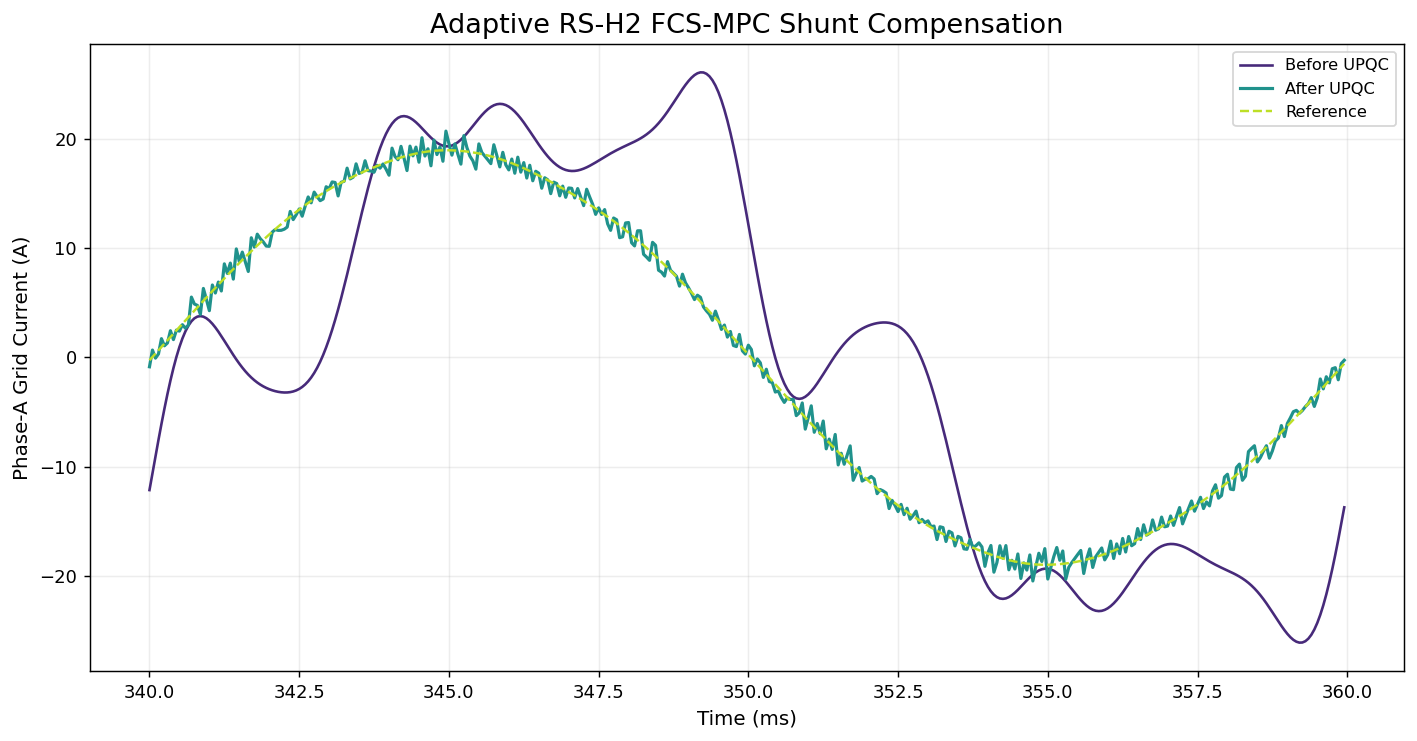

In [ ]:
SHUNT_GAMMA = 1.20
SHUNT_TOP_K = 4
SHUNT_LAMBDA_SW = 1e-4
SHUNT_LAMBDA_CMV = 1e-4

unit_voltage = (
    v_reference
    / V_PHASE_PEAK
)

pv_current_peak = (
    pv_power
    / (
        1.5
        * V_PHASE_PEAK
    )
)

i_pv = (
    pv_current_peak[:, None]
    * unit_voltage
)

p_load_inst = np.sum(
    v_load * i_load,
    axis=1
)

p_load_avg = lowpass(
    p_load_inst,
    tau=0.020,
    initial=np.mean(
        p_load_inst[:SPC]
    )
)

p_grid_ref = (
    p_load_avg
    - pv_power
)

i_grid_peak_ref = (
    p_grid_ref
    / (
        1.5
        * V_PHASE_PEAK
    )
)

i_grid_reference = (
    i_grid_peak_ref[:, None]
    * unit_voltage
)

i_comp_reference = (
    i_load
    - i_pv
    - i_grid_reference
)


def run_shunt_proposed(
    vpcc,
    iref,
    fs=None,
    ratio=SHUNT_RATIO,
    L=SHUNT_L,
    R=SHUNT_R,
    gamma=SHUNT_GAMMA,
    top_k=SHUNT_TOP_K,
    lambda_sw=SHUNT_LAMBDA_SW,
    lambda_cm=SHUNT_LAMBDA_CMV,
):
    if fs is None:
        fs = FS_SIM

    dt = 1 / fs
    n = len(vpcc)

    ic = np.zeros((n, 3))
    idx = np.zeros(n, dtype=int)

    prev_idx = 0

    for k in range(1, n):
        vm1, cm1 = matrix_candidates(
            vpcc[k],
            ratio
        )

        i1 = (
            ic[k - 1]
            + dt / L
            * (
                vm1
                - vpcc[k]
                - R * ic[k - 1]
            )
        )

        err1 = (
            i1
            - iref[k]
        ) / 30.0

        track1 = np.mean(
            err1 ** 2,
            axis=1
        )

        gate1 = np.exp(
            -track1 / 0.004
        )

        cost1 = (
            track1

            + gate1
            * lambda_sw
            * STATE_DISTANCE[prev_idx]

            + gate1
            * lambda_cm
            * (
                cm1
                / V_PHASE_PEAK
            ) ** 2
        )

        top = np.argpartition(
            cost1,
            min(
                top_k - 1,
                len(cost1) - 1
            )
        )[:top_k]

        if k < n - 1:
            vp2 = (
                2 * vpcc[k]
                - vpcc[k - 1]
            )

            ref2 = iref[k + 1]

        else:
            vp2 = vpcc[k]
            ref2 = iref[k]

        vm2, cm2 = matrix_candidates(
            vp2,
            ratio
        )

        i1t = i1[top]

        i2 = (
            i1t[:, None, :]

            + dt / L
            * (
                vm2[None, :, :]
                - vp2[None, None, :]
                - R
                * i1t[:, None, :]
            )
        )

        err2 = (
            i2
            - ref2[None, None, :]
        ) / 30.0

        track2 = np.mean(
            err2 ** 2,
            axis=2
        )

        gate2 = np.exp(
            -track2 / 0.004
        )

        cost2 = (
            track2

            + gate2
            * lambda_sw
            * STATE_DISTANCE[top, :]

            + gate2
            * lambda_cm
            * (
                cm2[None, :]
                / V_PHASE_PEAK
            ) ** 2
        )

        total = (
            cost1[top, None]
            + gamma * cost2
        )

        row, col = np.unravel_index(
            np.argmin(total),
            total.shape
        )

        j = int(top[row])

        ic[k] = i1[j]
        idx[k] = j

        prev_idx = j

    return ic, idx


i_shunt, shunt_state_idx = (
    run_shunt_proposed(
        v_load,
        i_comp_reference
    )
)

i_grid_before = (
    i_load
    - i_pv
)

i_grid = (
    i_load
    - i_pv
    - i_shunt
)

a, b = scenario_bounds["Harmonics"]

sl = slice(
    a + 2 * SPC,
    a + 3 * SPC
)

colors = VIRIDIS(
    np.linspace(0.12, 0.90, 3)
)

plt.figure()

plt.plot(
    t[sl] * 1000,
    i_grid_before[sl, 0],
    color=colors[0],
    lw=1.45,
    label="Before UPQC"
)

plt.plot(
    t[sl] * 1000,
    i_grid[sl, 0],
    color=colors[1],
    lw=1.75,
    label="After UPQC"
)

plt.plot(
    t[sl] * 1000,
    i_grid_reference[sl, 0],
    color=colors[2],
    ls="--",
    lw=1.35,
    label="Reference"
)

plt.xlabel("Time (ms)")
plt.ylabel("Phase-A Grid Current (A)")
plt.title("Adaptive RS-H2 FCS-MPC Shunt Compensation")
plt.legend()
finish_plot("stage12_shunt_proposed.png")

## Stage 13 — Active Power Sharing Between Load, PV-DG, and Grid

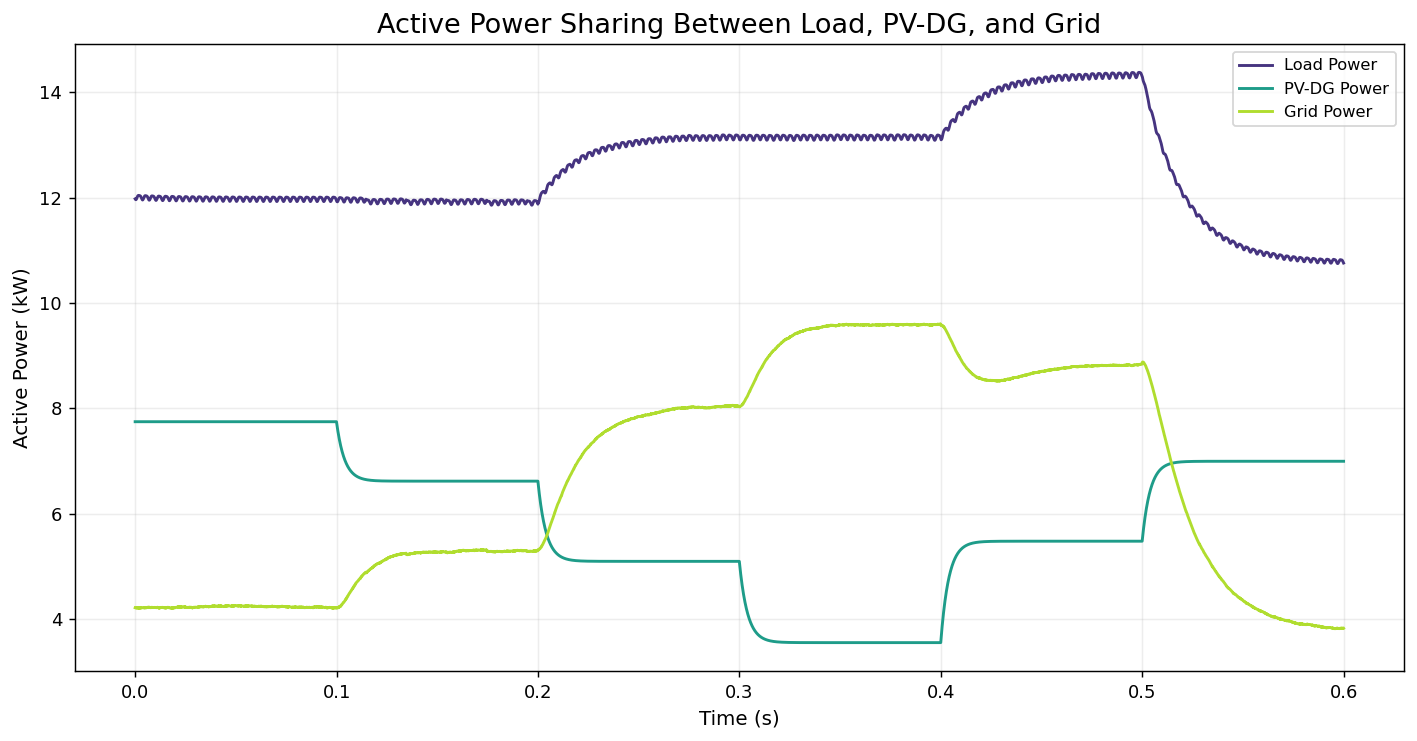

In [ ]:
p_grid_inst = np.sum(
    v_load * i_grid,
    axis=1
)

p_grid_avg = lowpass(
    p_grid_inst,
    tau=0.010,
    initial=np.mean(
        p_grid_inst[:SPC]
    )
)

plt.figure()

plt.plot(
    t,
    p_load_avg / 1000,
    color=VIRIDIS(0.15),
    lw=1.6,
    label="Load Power"
)

plt.plot(
    t,
    pv_power / 1000,
    color=VIRIDIS(0.55),
    lw=1.6,
    label="PV-DG Power"
)

plt.plot(
    t,
    p_grid_avg / 1000,
    color=VIRIDIS(0.88),
    lw=1.6,
    label="Grid Power"
)

plt.xlabel("Time (s)")
plt.ylabel("Active Power (kW)")
plt.title("Active Power Sharing Between Load, PV-DG, and Grid")
plt.legend()
finish_plot("stage13_power_sharing.png")

## Stage 14 — Power Quality Metrics and Scenario-Wise Results

,Scenario,V_RMS_Before_V,V_RMS_After_V,V_THD_Before_pct,V_THD_After_pct,I_THD_Before_pct,I_THD_After_pct,PF_Before,PF_After,PV_Power_kW,Grid_Power_kW
0,Pure_Sinusoidal,239.6004,239.6004,0.0000,0.0000,50.4599,1.7460,0.5393,0.9931,7.7440,4.2296
1,Sag,210.9705,239.0554,14.8462,1.9075,45.6491,1.6062,0.6269,0.9951,6.6154,5.2583
2,Swell,336.6866,239.6893,12.8268,0.7047,38.3367,1.2090,0.7422,0.9978,5.0924,7.8172
3,Harmonics,244.0723,239.4973,19.4104,1.0569,33.9977,1.3746,0.7978,0.9986,3.5487,9.5421
4,Sag_with_Harmonics,187.9162,239.4865,17.4601,1.0972,38.0815,1.5307,0.7454,0.9983,5.4739,8.7128
5,Swell_with_Harmonics,319.8835,239.6754,14.7710,0.8138,50.6172,2.1693,0.5350,0.9893,6.9921,4.3943


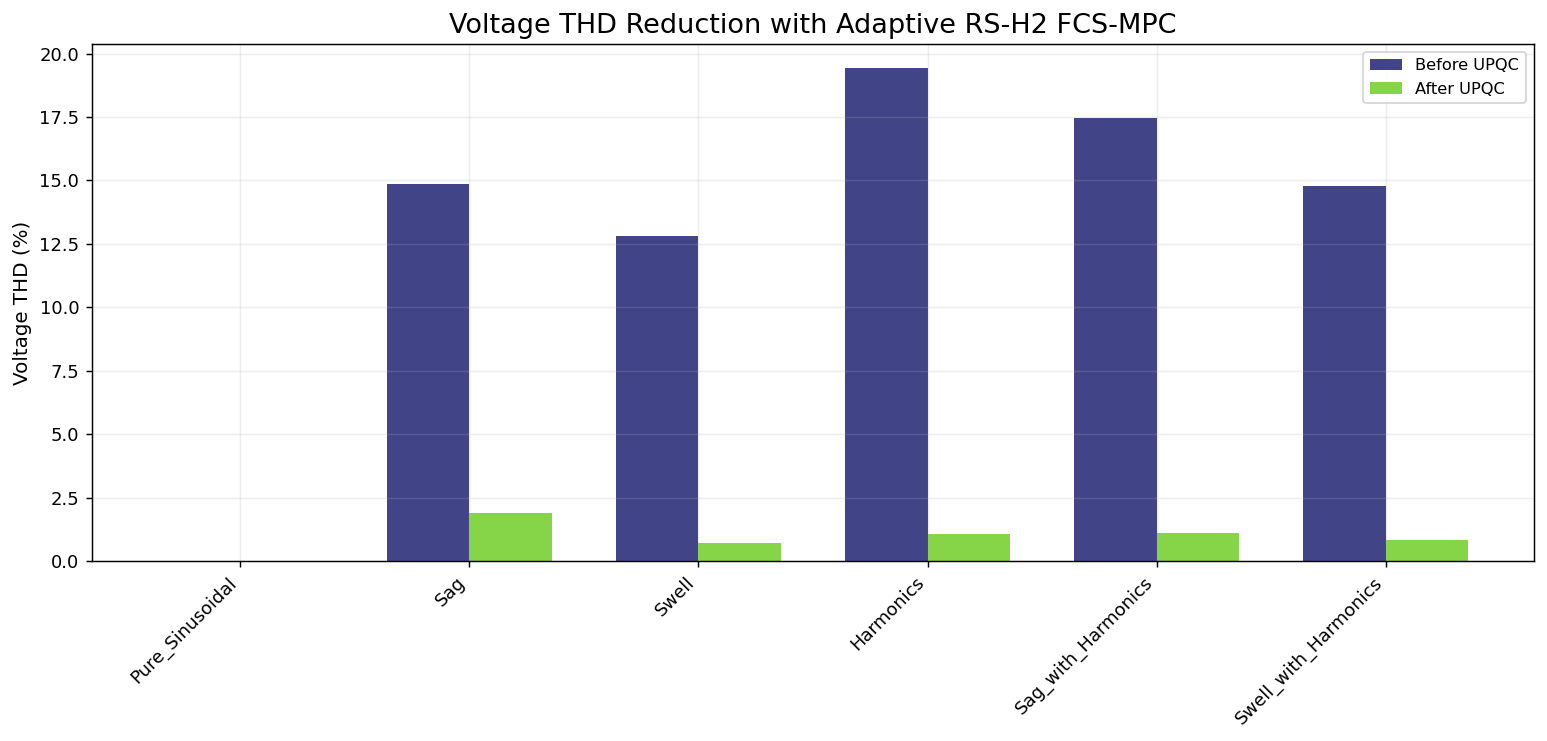

In [ ]:
def rms(x):
    return float(
        np.sqrt(
            np.mean(
                np.asarray(
                    x,
                    dtype=float
                ) ** 2
            )
        )
    )


def thd_percent(
    x,
    fs=None,
    f0=F_GRID,
    max_harmonic=25
):
    if fs is None:
        fs = FS_SIM

    x = np.asarray(
        x,
        dtype=float
    )

    n = len(x)

    sp = np.abs(
        rfft(x)
    ) / n

    fr = rfftfreq(
        n,
        1 / fs
    )

    k1 = int(
        np.argmin(
            np.abs(fr - f0)
        )
    )

    fundamental = sp[k1]

    harmonic_energy = 0.0

    for h in range(
        2,
        max_harmonic + 1
    ):
        if h * f0 > fr[-1]:
            break

        kh = int(
            np.argmin(
                np.abs(
                    fr - h * f0
                )
            )
        )

        harmonic_energy += (
            sp[kh] ** 2
        )

    return float(
        100
        * np.sqrt(harmonic_energy)
        / (
            fundamental
            + 1e-12
        )
    )


def mean_3ph_thd(xabc):
    return float(
        np.mean([
            thd_percent(
                xabc[:, p]
            )
            for p in range(3)
        ])
    )


def pf_3ph(vabc, iabc):
    p = float(
        np.mean(
            np.sum(
                vabc * iabc,
                axis=1
            )
        )
    )

    vr = np.mean([
        rms(vabc[:, q])
        for q in range(3)
    ])

    ir = np.mean([
        rms(iabc[:, q])
        for q in range(3)
    ])

    return float(
        np.clip(
            p
            / (
                3 * vr * ir
                + 1e-12
            ),
            -1,
            1
        )
    )


def switching_state_transition_rate_khz(idx):
    if idx is None or len(idx) < 2:
        return np.nan

    changed = np.any(
        SWITCH_STATES[idx[1:]]
        != SWITCH_STATES[idx[:-1]],
        axis=1
    )

    return float(
        np.mean(changed)
        * FS_SIM
        / 1000
    )


def common_mode_rms(vin, idx):
    if idx is None:
        return np.nan

    raw = vin[
        np.arange(len(vin))[:, None],
        SWITCH_STATES[idx]
    ]

    cm = raw.mean(axis=1)

    return rms(cm)


scenario_rows = []

for cls in MAIN_SCENARIOS:
    a, b = scenario_bounds[cls]

    sl = slice(
        a + SPC,
        b
    )

    vb = v_source[sl]
    va = v_load[sl]

    ib = i_grid_before[sl]
    ia = i_grid[sl]

    scenario_rows.append({
        "Scenario": cls,

        "V_RMS_Before_V":
            np.mean([
                rms(vb[:, p])
                for p in range(3)
            ]),

        "V_RMS_After_V":
            np.mean([
                rms(va[:, p])
                for p in range(3)
            ]),

        "V_THD_Before_pct":
            mean_3ph_thd(vb),

        "V_THD_After_pct":
            mean_3ph_thd(va),

        "I_THD_Before_pct":
            mean_3ph_thd(ib),

        "I_THD_After_pct":
            mean_3ph_thd(ia),

        "PF_Before":
            pf_3ph(va, ib),

        "PF_After":
            pf_3ph(va, ia),

        "PV_Power_kW":
            float(
                np.mean(
                    pv_power[sl]
                ) / 1000
            ),

        "Grid_Power_kW":
            float(
                np.mean(
                    p_grid_avg[sl]
                ) / 1000
            ),
    })

scenario_metrics = pd.DataFrame(
    scenario_rows
)

display(
    scenario_metrics.round(4)
)

x = np.arange(
    len(scenario_metrics)
)

w = 0.36
colors = VIRIDIS([0.20, 0.82])

plt.figure(figsize=(12, 5.8))

plt.bar(
    x - w / 2,
    scenario_metrics["V_THD_Before_pct"],
    w,
    color=colors[0],
    label="Before UPQC"
)

plt.bar(
    x + w / 2,
    scenario_metrics["V_THD_After_pct"],
    w,
    color=colors[1],
    label="After UPQC"
)

plt.xticks(
    x,
    scenario_metrics["Scenario"],
    rotation=45,
    ha="right"
)

plt.ylabel("Voltage THD (%)")
plt.title("Voltage THD Reduction with Adaptive RS-H2 FCS-MPC")
plt.legend()
finish_plot("stage14_voltage_thd.png")

## Stage 15 — Grid Current Harmonic Spectrum

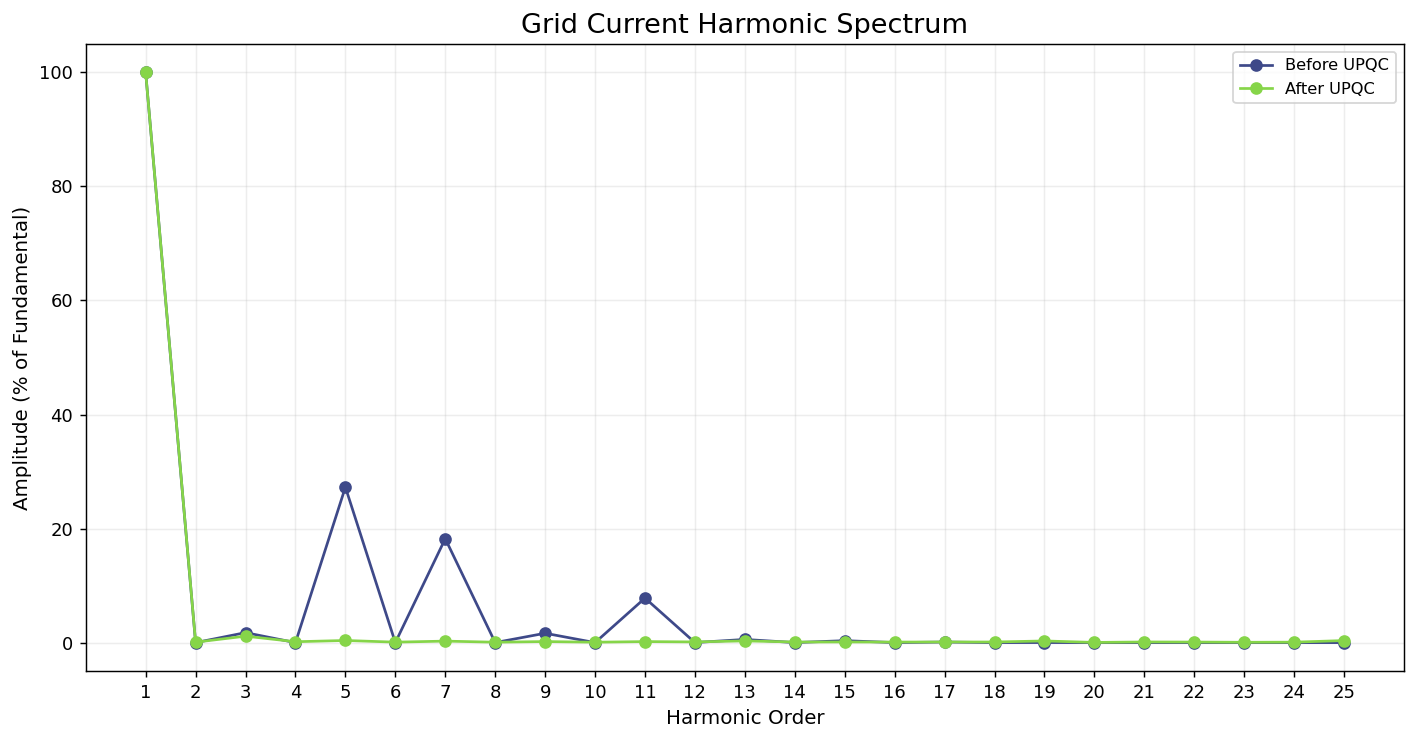

In [ ]:
def harmonic_spectrum(
    x,
    max_order=25
):
    x = np.asarray(
        x,
        dtype=float
    )

    n = len(x)

    sp = np.abs(
        rfft(x)
    ) / n

    fr = rfftfreq(
        n,
        1 / FS_SIM
    )

    k1 = np.argmin(
        np.abs(fr - F_GRID)
    )

    fundamental = (
        sp[k1]
        + 1e-12
    )

    orders = np.arange(
        1,
        max_order + 1
    )

    amps = []

    for h in orders:
        kh = np.argmin(
            np.abs(
                fr
                - h * F_GRID
            )
        )

        amps.append(
            100
            * sp[kh]
            / fundamental
        )

    return (
        orders,
        np.asarray(amps)
    )


a, b = scenario_bounds["Harmonics"]

sl = slice(
    a + SPC,
    b
)

orders, spec_before = harmonic_spectrum(
    i_grid_before[sl, 0]
)

_, spec_after = harmonic_spectrum(
    i_grid[sl, 0]
)

colors = VIRIDIS([0.22, 0.82])

plt.figure()

plt.plot(
    orders,
    spec_before,
    marker="o",
    color=colors[0],
    label="Before UPQC"
)

plt.plot(
    orders,
    spec_after,
    marker="o",
    color=colors[1],
    label="After UPQC"
)

plt.xticks(orders)
plt.xlabel("Harmonic Order")
plt.ylabel("Amplitude (% of Fundamental)")
plt.title("Grid Current Harmonic Spectrum")
plt.legend()
finish_plot("stage15_harmonic_spectrum.png")

## Stage 16 — Fair Internal Baseline Controllers

In [ ]:
def average_matrix_output(
    vin,
    target,
    ratio
):
    target = np.asarray(
        target,
        dtype=float
    )

    target = (
        target
        - target.mean()
    )

    desired = (
        target
        / ratio
    )

    vmin = np.min(vin)
    vmax = np.max(vin)

    cm = 0.5 * (
        (
            vmin
            - desired.min()
        )
        +
        (
            vmax
            - desired.max()
        )
    )

    d = np.clip(
        desired + cm,
        vmin,
        vmax
    )

    out = ratio * d

    return (
        out
        - out.mean()
    )


def run_series_pi(
    vs,
    vr,
    Kpv=0.20,
    Kiv=50.0,
    Kpi=10.0
):
    n = len(vs)

    vc = np.zeros((n, 3))
    i_f = np.zeros((n, 3))
    integ = np.zeros(3)

    for k in range(1, n):
        e = (
            vr[k]
            - vs[k]
            - vc[k - 1]
        )

        integ = np.clip(
            integ + e * DT,
            -3,
            3
        )

        iref = (
            Kpv * e
            + Kiv * integ
        )

        vmcmd = (
            vc[k - 1]
            + SERIES_R
            * i_f[k - 1]
            + Kpi
            * (
                iref
                - i_f[k - 1]
            )
        )

        vm = average_matrix_output(
            vs[k],
            vmcmd,
            SERIES_RATIO
        )

        i_f[k] = (
            i_f[k - 1]
            + DT / SERIES_L
            * (
                vm
                - vc[k - 1]
                - SERIES_R
                * i_f[k - 1]
            )
        )

        vc[k] = (
            vc[k - 1]
            + DT / SERIES_C
            * i_f[k]
        )

    return (
        vs + vc,
        vc,
        None
    )


def run_series_deadbeat(
    vs,
    vr
):
    n = len(vs)

    vc = np.zeros((n, 3))
    i_f = np.zeros((n, 3))
    idx = np.zeros(n, dtype=int)

    for k in range(1, n):
        vcref = (
            vr[k]
            - vs[k]
        )

        i_des = (
            (
                vcref
                - vc[k - 1]
            )
            * SERIES_C
            / DT
        )

        vm_des = (
            vc[k - 1]
            + SERIES_R
            * i_f[k - 1]

            + SERIES_L
            * (
                i_des
                - i_f[k - 1]
            )
            / DT
        )

        vm, _ = matrix_candidates(
            vs[k],
            SERIES_RATIO
        )

        j = int(
            np.argmin(
                np.mean(
                    (
                        (
                            vm
                            - vm_des
                        )
                        / V_PHASE_PEAK
                    ) ** 2,
                    axis=1
                )
            )
        )

        i_f[k] = (
            i_f[k - 1]
            + DT / SERIES_L
            * (
                vm[j]
                - vc[k - 1]
                - SERIES_R
                * i_f[k - 1]
            )
        )

        vc[k] = (
            vc[k - 1]
            + DT / SERIES_C
            * i_f[k]
        )

        idx[k] = j

    return (
        vs + vc,
        vc,
        idx
    )


def run_series_fcs_h1(
    vs,
    vr
):
    n = len(vs)

    vc = np.zeros((n, 3))
    i_f = np.zeros((n, 3))
    idx = np.zeros(n, dtype=int)

    for k in range(1, n):
        vm, _ = matrix_candidates(
            vs[k],
            SERIES_RATIO
        )

        ip = (
            i_f[k - 1]
            + DT / SERIES_L
            * (
                vm
                - vc[k - 1]
                - SERIES_R
                * i_f[k - 1]
            )
        )

        vp = (
            vc[k - 1]
            + DT / SERIES_C
            * ip
        )

        e = np.mean(
            (
                (
                    vs[k]
                    + vp
                    - vr[k]
                )
                / V_PHASE_PEAK
            ) ** 2,
            axis=1
        )

        j = int(
            np.argmin(e)
        )

        i_f[k] = ip[j]
        vc[k] = vp[j]
        idx[k] = j

    return (
        vs + vc,
        vc,
        idx
    )


def run_shunt_pi(
    vpcc,
    iref,
    Kp=25.0,
    Ki=500.0
):
    n = len(vpcc)

    ic = np.zeros((n, 3))
    integ = np.zeros(3)

    for k in range(1, n):
        e = (
            iref[k]
            - ic[k - 1]
        )

        integ = np.clip(
            integ + e * DT,
            -2,
            2
        )

        vmcmd = (
            vpcc[k]
            + SHUNT_R
            * ic[k - 1]
            + Kp * e
            + Ki * integ
        )

        vm = average_matrix_output(
            vpcc[k],
            vmcmd,
            SHUNT_RATIO
        )

        ic[k] = (
            ic[k - 1]
            + DT / SHUNT_L
            * (
                vm
                - vpcc[k]
                - SHUNT_R
                * ic[k - 1]
            )
        )

    return ic, None


def run_shunt_deadbeat(
    vpcc,
    iref
):
    n = len(vpcc)

    ic = np.zeros((n, 3))
    idx = np.zeros(n, dtype=int)

    for k in range(1, n):
        vm_des = (
            vpcc[k]
            + SHUNT_R
            * ic[k - 1]

            + SHUNT_L
            * (
                iref[k]
                - ic[k - 1]
            )
            / DT
        )

        vm, _ = matrix_candidates(
            vpcc[k],
            SHUNT_RATIO
        )

        j = int(
            np.argmin(
                np.mean(
                    (
                        (
                            vm
                            - vm_des
                        )
                        /
                        (
                            V_PHASE_PEAK
                            * SHUNT_RATIO
                        )
                    ) ** 2,
                    axis=1
                )
            )
        )

        ic[k] = (
            ic[k - 1]
            + DT / SHUNT_L
            * (
                vm[j]
                - vpcc[k]
                - SHUNT_R
                * ic[k - 1]
            )
        )

        idx[k] = j

    return ic, idx


def run_shunt_fcs_h1(
    vpcc,
    iref
):
    n = len(vpcc)

    ic = np.zeros((n, 3))
    idx = np.zeros(n, dtype=int)

    for k in range(1, n):
        vm, _ = matrix_candidates(
            vpcc[k],
            SHUNT_RATIO
        )

        ip = (
            ic[k - 1]
            + DT / SHUNT_L
            * (
                vm
                - vpcc[k]
                - SHUNT_R
                * ic[k - 1]
            )
        )

        e = np.mean(
            (
                (
                    ip
                    - iref[k]
                )
                / 30.0
            ) ** 2,
            axis=1
        )

        j = int(
            np.argmin(e)
        )

        ic[k] = ip[j]
        idx[k] = j

    return ic, idx

## Stage 17 — Proposed vs Internal Baseline Comparison

,Method,V_THD_pct,I_THD_pct,RMS_Error_pct,PF,PQI,Multiobjective_Index,Switching_State_Transition_Rate_kHz,Series_CMV_RMS_V,Shunt_CMV_RMS_V,Runtime_s
0,SRF-PI,1.6310,17.0092,0.1032,0.9433,21.5795,22.1395,20.0000,NaN,NaN,1.3714
1,Deadbeat-Predictive,0.6065,1.4266,0.1233,0.9509,4.6108,5.3699,16.4755,195.3547,102.3733,1.1346
2,1-Step-FCS,0.6065,1.4266,0.1233,0.9509,4.6108,5.3605,16.1147,196.1040,102.3733,1.0897
3,Proposed-Adaptive-RS-H2-FCS,0.5259,0.7626,0.1093,0.9514,3.8254,4.5221,15.6030,158.8480,100.9867,4.9746


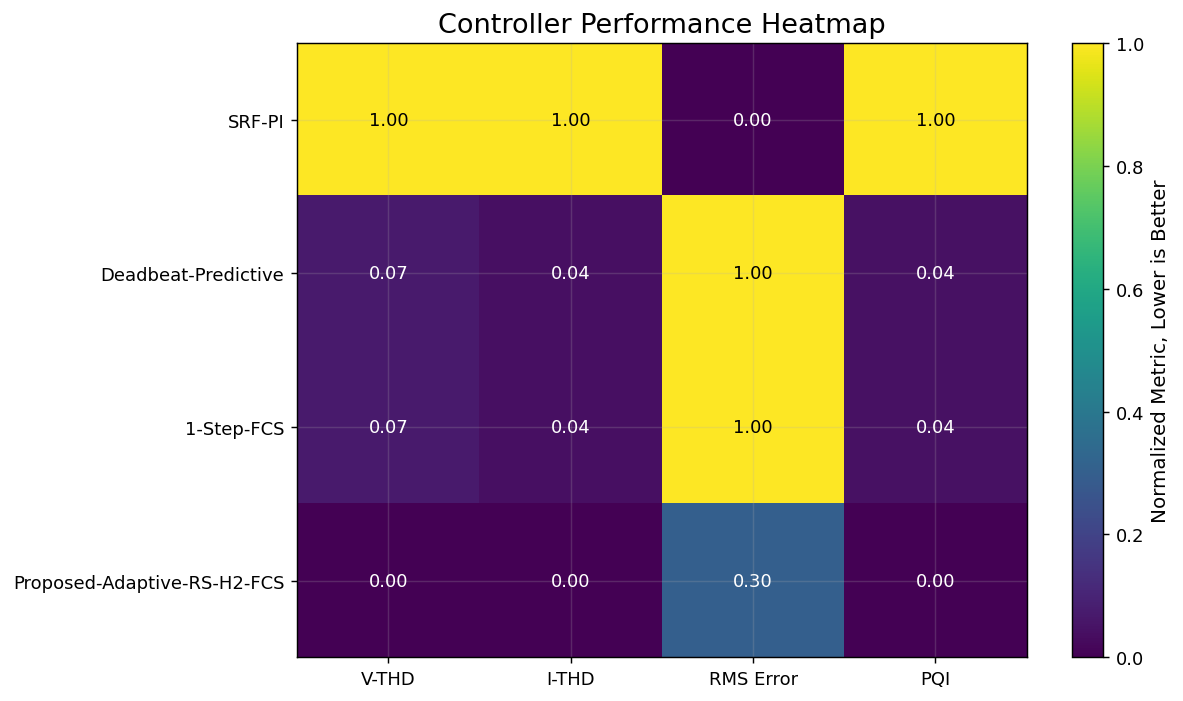

In [ ]:
METHODS = [
    "SRF-PI",
    "Deadbeat-Predictive",
    "1-Step-FCS",
    "Proposed-Adaptive-RS-H2-FCS",
]


def evaluate_complete_controller(
    method,
    vs,
    vr,
    iload,
    ppv
):
    start = time.perf_counter()

    if method == "SRF-PI":
        vl, _, sidx = run_series_pi(
            vs,
            vr
        )

    elif method == "Deadbeat-Predictive":
        vl, _, sidx = run_series_deadbeat(
            vs,
            vr
        )

    elif method == "1-Step-FCS":
        vl, _, sidx = run_series_fcs_h1(
            vs,
            vr
        )

    elif method == "Proposed-Adaptive-RS-H2-FCS":
        vl, _, _, sidx = run_series_proposed(
            vs,
            vr
        )

    else:
        raise ValueError(method)

    unit = (
        vr
        / V_PHASE_PEAK
    )

    ipv = (
        (
            ppv
            / (
                1.5
                * V_PHASE_PEAK
            )
        )[:, None]
        * unit
    )

    pinst = np.sum(
        vl * iload,
        axis=1
    )

    pavg = lowpass(
        pinst,
        tau=0.020,
        initial=np.mean(
            pinst[:SPC]
        )
    )

    pgrid = (
        pavg
        - ppv
    )

    igrid_ref = (
        (
            pgrid
            / (
                1.5
                * V_PHASE_PEAK
            )
        )[:, None]
        * unit
    )

    icref = (
        iload
        - ipv
        - igrid_ref
    )

    if method == "SRF-PI":
        ic, qidx = run_shunt_pi(
            vl,
            icref
        )

    elif method == "Deadbeat-Predictive":
        ic, qidx = run_shunt_deadbeat(
            vl,
            icref
        )

    elif method == "1-Step-FCS":
        ic, qidx = run_shunt_fcs_h1(
            vl,
            icref
        )

    else:
        ic, qidx = run_shunt_proposed(
            vl,
            icref
        )

    igrid = (
        iload
        - ipv
        - ic
    )

    elapsed = (
        time.perf_counter()
        - start
    )

    sl = slice(
        SPC,
        None
    )

    vthd = mean_3ph_thd(
        vl[sl]
    )

    ithd = mean_3ph_thd(
        igrid[sl]
    )

    rms_error = float(
        np.mean([
            abs(
                rms(vl[sl, p])
                - V_PHASE_RMS
            )
            / V_PHASE_RMS
            * 100

            for p in range(3)
        ])
    )

    pf = pf_3ph(
        vl[sl],
        igrid[sl]
    )

    if sidx is None:
        series_event_rate = (
            FS_SIM / 1000
        )

        series_cmv = np.nan

    else:
        series_event_rate = (
            switching_state_transition_rate_khz(
                sidx
            )
        )

        series_cmv = common_mode_rms(
            vs,
            sidx
        )

    if qidx is None:
        shunt_event_rate = (
            FS_SIM / 1000
        )

        shunt_cmv = np.nan

    else:
        shunt_event_rate = (
            switching_state_transition_rate_khz(
                qidx
            )
        )

        shunt_cmv = common_mode_rms(
            vl,
            qidx
        )

    pqi = (
        vthd
        + ithd
        + rms_error
        + 50 * (1 - pf)
    )

    cmv_total = np.nansum([
        series_cmv,
        shunt_cmv
    ])

    event_mean = np.nanmean([
        series_event_rate,
        shunt_event_rate
    ])

    multiobjective_index = (
        pqi
        + 0.014
        * (
            series_event_rate
            + shunt_event_rate
        )
        + 0.001
        * cmv_total
    )

    return {
        "Method": method,
        "V_THD_pct": vthd,
        "I_THD_pct": ithd,
        "RMS_Error_pct": rms_error,
        "PF": pf,
        "PQI": pqi,
        "Multiobjective_Index": multiobjective_index,
        "Switching_State_Transition_Rate_kHz": event_mean,
        "Series_CMV_RMS_V": series_cmv,
        "Shunt_CMV_RMS_V": shunt_cmv,
        "Runtime_s": elapsed,
    }


comparison_rows = []

for method in METHODS:
    comparison_rows.append(
        evaluate_complete_controller(
            method,
            v_source,
            v_reference,
            i_load,
            pv_power
        )
    )

comparison = pd.DataFrame(
    comparison_rows
)

display(
    comparison.round(4)
)

metrics_plot = [
    "V_THD_pct",
    "I_THD_pct",
    "RMS_Error_pct",
    "PQI",
]

norm = comparison[
    metrics_plot
].copy()

for col in metrics_plot:
    lo = norm[col].min()
    hi = norm[col].max()

    norm[col] = (
        norm[col] - lo
    ) / (
        hi - lo
        + 1e-12
    )

heat = norm.to_numpy()

plt.figure(figsize=(9.5, 5.5))

img = plt.imshow(
    heat,
    cmap="viridis",
    aspect="auto"
)

plt.colorbar(
    img,
    label="Normalized Metric, Lower is Better"
)

plt.xticks(
    np.arange(len(metrics_plot)),
    [
        "V-THD",
        "I-THD",
        "RMS Error",
        "PQI",
    ]
)

plt.yticks(
    np.arange(len(comparison)),
    comparison["Method"]
)

for r in range(
    heat.shape[0]
):
    for c in range(
        heat.shape[1]
    ):
        plt.text(
            c,
            r,
            f"{heat[r, c]:.2f}",
            ha="center",
            va="center",
            color=(
                "white"
                if heat[r, c] < 0.55
                else "black"
            )
        )

plt.title("Controller Performance Heatmap")
finish_plot("stage17_controller_heatmap.png")

## Stage 18 — Paired Statistical Significance with Holm Correction

,Method,V_THD_pct,I_THD_pct,RMS_Error_pct,PQI,Class,Sample_Index
0,SRF-PI,8.913598,12.155121,1.740595,122.161315,Sag,771
1,Deadbeat-Predictive,11.572534,5.028740,2.653577,118.739698,Sag,771
2,1-Step-FCS,11.572534,5.028740,2.653577,118.739698,Sag,771
3,Proposed-Adaptive-RS-H2-FCS,11.669870,4.938098,2.384838,118.491113,Sag,771
4,SRF-PI,39.181902,63.452286,46.934463,231.763243,Sag,438


,Metric,Baseline,Median_Baseline_minus_Proposed,CI95_Low,CI95_High,Wilcoxon_W,p_raw,Rank_Biserial,Proposed_Better_pct,Tied_pct,Proposed_Not_Better_Count,p_Holm,Significant_0.05
0,I_THD_pct,SRF-PI,8.056958,7.910669,8.305726,325.0,0.000000,1.000000,100.0,0.0,0,0.000000,True
1,I_THD_pct,Deadbeat-Predictive,0.374772,0.230896,0.423634,324.0,0.000000,0.993846,96.0,0.0,1,0.000000,True
2,I_THD_pct,1-Step-FCS,0.374772,0.230896,0.423634,324.0,0.000000,0.993846,96.0,0.0,1,0.000000,True
3,RMS_Error_pct,SRF-PI,0.356405,0.103941,0.624566,256.0,0.005255,0.575385,80.0,0.0,5,0.005671,True
4,RMS_Error_pct,Deadbeat-Predictive,0.037538,0.001181,0.074525,267.0,0.001890,0.643077,68.0,0.0,8,0.005671,True
5,RMS_Error_pct,1-Step-FCS,0.037538,0.001181,0.074525,267.0,0.001890,0.643077,68.0,0.0,8,0.005671,True
6,PQI,SRF-PI,10.989366,9.911305,11.953503,325.0,0.000000,1.000000,100.0,0.0,0,0.000000,True
7,PQI,Deadbeat-Predictive,0.310792,0.161328,0.473135,314.0,0.000002,0.932308,92.0,0.0,2,0.000003,True
8,PQI,1-Step-FCS,0.310792,0.161328,0.473135,314.0,0.000002,0.932308,92.0,0.0,2,0.000003,True


,Metric,Friedman_Chi2,p_value
0,I_THD_pct,65.351020,0.000000
1,RMS_Error_pct,20.740260,0.000119
2,PQI,64.812766,0.000000


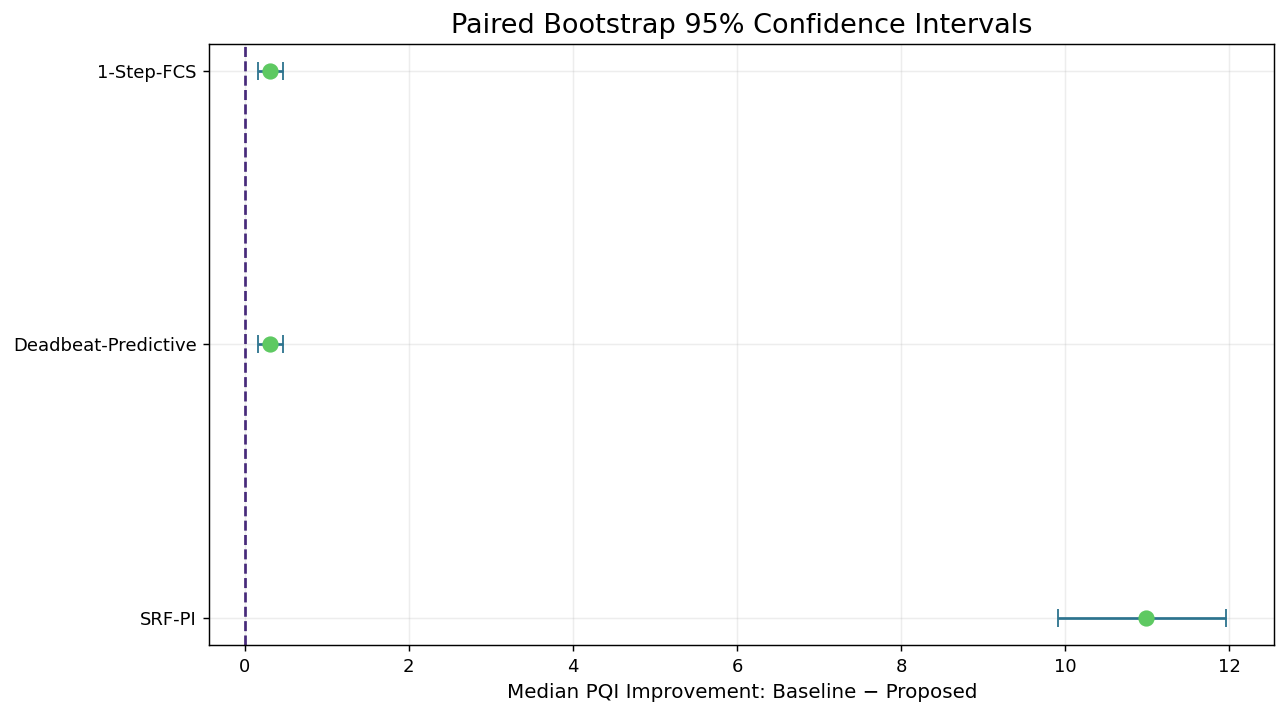

,Metric,Baseline,Median_Baseline_minus_Proposed,CI95_Low,CI95_High,Rank_Biserial,Proposed_Better_pct,Proposed_Not_Better_Count,p_Holm,Significant_0.05
0,I_THD_pct,SRF-PI,8.056958,7.910669,8.305726,1.000000,100.0,0,0.000000,True
1,I_THD_pct,Deadbeat-Predictive,0.374772,0.230896,0.423634,0.993846,96.0,1,0.000000,True
2,I_THD_pct,1-Step-FCS,0.374772,0.230896,0.423634,0.993846,96.0,1,0.000000,True
3,RMS_Error_pct,SRF-PI,0.356405,0.103941,0.624566,0.575385,80.0,5,0.005671,True
4,RMS_Error_pct,Deadbeat-Predictive,0.037538,0.001181,0.074525,0.643077,68.0,8,0.005671,True
5,RMS_Error_pct,1-Step-FCS,0.037538,0.001181,0.074525,0.643077,68.0,8,0.005671,True
6,PQI,SRF-PI,10.989366,9.911305,11.953503,1.000000,100.0,0,0.000000,True
7,PQI,Deadbeat-Predictive,0.310792,0.161328,0.473135,0.932308,92.0,2,0.000003,True
8,PQI,1-Step-FCS,0.310792,0.161328,0.473135,0.932308,92.0,2,0.000003,True


In [ ]:
STAT_CLASSES = [
    "Sag",
    "Swell",
    "Harmonics",
    "Sag_with_Harmonics",
    "Swell_with_Harmonics",
]

STAT_SAMPLES_PER_CLASS = 5

rng = np.random.default_rng(42)

selected = {
    cls: rng.choice(
        1000,
        size=STAT_SAMPLES_PER_CLASS,
        replace=False
    )
    for cls in STAT_CLASSES
}


def make_voltage_trial(
    cls,
    sample_idx,
    cycles=3
):
    x = align_fundamental(
        pq_data[cls][sample_idx]
    )

    cyc = three_phase_positive_sequence(x)

    vs = np.tile(
        cyc,
        (cycles, 1)
    )

    theta, _ = robust_positive_sequence_sync(vs)

    vr = make_vref(theta)

    return vs, vr


def make_trial_load_and_pv(
    vr,
    pv_level=5600.0
):
    n = len(vr)

    theta = np.unwrap(
        np.arctan2(
            vr[:, 0],
            np.gradient(
                vr[:, 0]
            ) / (
                2 * np.pi
                * F_GRID
                + 1e-12
            )
        )
    )

    unit = (
        vr
        / V_PHASE_PEAK
    )

    ppv = np.ones(n) * pv_level

    ipv = (
        (
            ppv
            / (
                1.5
                * V_PHASE_PEAK
            )
        )[:, None]
        * unit
    )

    il = np.zeros(
        (n, 3)
    )

    base_theta = np.angle(
        hilbert(
            vr[:, 0]
        )
    )

    for p, off in enumerate(
        phase_offsets
    ):
        th = (
            base_theta
            + off
        )

        il[:, p] = (
            I1_PEAK
            * np.sin(
                th
                - LOAD_PF_ANGLE
            )

            + 0.22
            * I1_PEAK
            * np.sin(
                5 * th
                + 0.30
            )

            + 0.14
            * I1_PEAK
            * np.sin(
                7 * th
                - 0.20
            )

            + 0.06
            * I1_PEAK
            * np.sin(
                11 * th
                + 0.10
            )
        )

    return il, ppv, ipv


def evaluate_stat_trial(
    method,
    vs,
    vr,
    il,
    ppv
):
    result = evaluate_complete_controller(
        method,
        vs,
        vr,
        il,
        ppv
    )

    return {
        "Method": method,
        "V_THD_pct": result["V_THD_pct"],
        "I_THD_pct": result["I_THD_pct"],
        "RMS_Error_pct": result["RMS_Error_pct"],
        "PQI": result["PQI"],
    }


stat_rows = []

for cls in STAT_CLASSES:
    for sample_idx in selected[cls]:

        vs_trial, vr_trial = make_voltage_trial(
            cls,
            int(sample_idx)
        )

        il_trial, ppv_trial, _ = make_trial_load_and_pv(
            vr_trial
        )

        for method in METHODS:

            result = evaluate_stat_trial(
                method,
                vs_trial,
                vr_trial,
                il_trial,
                ppv_trial
            )

            result.update({
                "Class": cls,
                "Sample_Index":
                    int(sample_idx),
            })

            stat_rows.append(result)

stat_results = pd.DataFrame(
    stat_rows
)

display(
    stat_results.head()
)


def holm_adjust(pvalues):
    p = np.asarray(
        pvalues,
        dtype=float
    )

    m = len(p)

    order = np.argsort(p)

    adjusted = np.empty(m)

    running = 0.0

    for rank, idx in enumerate(order):
        value = (
            (m - rank)
            * p[idx]
        )

        running = max(
            running,
            value
        )

        adjusted[idx] = min(
            running,
            1.0
        )

    return adjusted


def rank_biserial_from_differences(d):
    d = np.asarray(
        d,
        dtype=float
    )

    d = d[d != 0]

    if len(d) == 0:
        return 0.0

    ranks = pd.Series(
        np.abs(d)
    ).rank(
        method="average"
    ).to_numpy()

    rpos = np.sum(
        ranks[d > 0]
    )

    rneg = np.sum(
        ranks[d < 0]
    )

    return float(
        (
            rpos - rneg
        )
        /
        (
            rpos + rneg
            + 1e-12
        )
    )


def bootstrap_median_ci(
    d,
    n_boot=2500,
    seed=42
):
    d = np.asarray(
        d,
        dtype=float
    )

    rr = np.random.default_rng(seed)

    meds = np.empty(
        n_boot
    )

    for b in range(n_boot):
        meds[b] = np.median(
            rr.choice(
                d,
                size=len(d),
                replace=True
            )
        )

    return np.percentile(
        meds,
        [2.5, 97.5]
    )


proposed_name = (
    "Proposed-Adaptive-RS-H2-FCS"
)

prop = stat_results[
    stat_results["Method"]
    == proposed_name
].sort_values(
    ["Class", "Sample_Index"]
)

test_metrics = [
    "I_THD_pct",
    "RMS_Error_pct",
    "PQI",
]

baseline_names = [
    "SRF-PI",
    "Deadbeat-Predictive",
    "1-Step-FCS",
]

test_rows = []

for metric in test_metrics:
    raw_p = []
    temp = []

    for baseline in baseline_names:

        base = stat_results[
            stat_results["Method"]
            == baseline
        ].sort_values(
            ["Class", "Sample_Index"]
        )

        d = (
            base[metric].to_numpy()
            - prop[metric].to_numpy()
        )

        try:
            w, p = wilcoxon(
                d,
                alternative="greater",
                zero_method="wilcox"
            )

        except Exception:
            w, p = np.nan, 1.0

        ci = bootstrap_median_ci(d)

        temp.append({
            "Metric": metric,
            "Baseline": baseline,

            "Median_Baseline_minus_Proposed":
                np.median(d),

            "CI95_Low":
                ci[0],

            "CI95_High":
                ci[1],

            "Wilcoxon_W":
                w,

            "p_raw":
                p,

            "Rank_Biserial":
                rank_biserial_from_differences(d),

            "Proposed_Better_pct":
                100 * np.mean(d > 0),

            "Tied_pct":
                100 * np.mean(np.isclose(d, 0.0, atol=1e-12)),

            "Proposed_Not_Better_Count":
                int(np.sum(d <= 0)),
        })

        raw_p.append(p)

    adjusted = holm_adjust(
        raw_p
    )

    for row, padj in zip(
        temp,
        adjusted
    ):
        row["p_Holm"] = padj

        row["Significant_0.05"] = (
            padj < 0.05
        )

        test_rows.append(row)

significance = pd.DataFrame(
    test_rows
)

display(
    significance.round(6)
)

friedman_rows = []

for metric in test_metrics:

    arrays = []

    for method in METHODS:

        arrays.append(
            stat_results[
                stat_results["Method"]
                == method
            ].sort_values(
                ["Class", "Sample_Index"]
            )[metric].to_numpy()
        )

    stat, p = friedmanchisquare(
        *arrays
    )

    friedman_rows.append({
        "Metric": metric,
        "Friedman_Chi2": stat,
        "p_value": p,
    })

friedman_table = pd.DataFrame(
    friedman_rows
)

display(
    friedman_table.round(6)
)

pqi_sig = significance[
    significance["Metric"]
    == "PQI"
].copy()

y = np.arange(
    len(pqi_sig)
)

mid = pqi_sig[
    "Median_Baseline_minus_Proposed"
].to_numpy()

lo = (
    mid
    - pqi_sig["CI95_Low"].to_numpy()
)

hi = (
    pqi_sig["CI95_High"].to_numpy()
    - mid
)

plt.figure(figsize=(10, 5.6))

plt.errorbar(
    mid,
    y,
    xerr=[lo, hi],
    fmt="o",
    ms=8,
    capsize=5,
    color=VIRIDIS(0.75),
    ecolor=VIRIDIS(0.38)
)

plt.axvline(
    0,
    color=VIRIDIS(0.12),
    ls="--"
)

plt.yticks(
    y,
    pqi_sig["Baseline"]
)

plt.xlabel("Median PQI Improvement: Baseline − Proposed")
plt.title("Paired Bootstrap 95% Confidence Intervals")
finish_plot("stage18_statistical_significance.png")

# Aggregate paired evidence summary.
# The inferential claim is made at the paired-population level.
# No claim is made that the proposed controller wins every individual trial.
aggregate_statistical_summary = significance[[
    "Metric",
    "Baseline",
    "Median_Baseline_minus_Proposed",
    "CI95_Low",
    "CI95_High",
    "Rank_Biserial",
    "Proposed_Better_pct",
    "Proposed_Not_Better_Count",
    "p_Holm",
    "Significant_0.05",
]].copy()

display(aggregate_statistical_summary.round(6))


## Stage 19 — Ablation Study

,Variant,V_THD_pct,I_THD_pct,RMS_Error_pct,PF,PQI,Multiobjective_Index,Switching_State_Transition_Rate_kHz,Series_CMV_RMS_V,Shunt_CMV_RMS_V
0,Full Proposed,0.5259,0.7626,0.1093,0.9514,3.8254,4.5221,15.6030,158.8480,100.9867
1,No H2 Lookahead,0.5395,1.3346,0.1128,0.9510,4.4376,5.1301,15.4555,158.6378,101.0638
2,No Switching Penalty,0.5931,0.8288,0.1362,0.9515,3.9853,4.6982,16.0672,161.4171,101.5973
3,No CMV Penalty,0.5632,0.8557,0.1217,0.9514,3.9700,4.7042,15.6930,193.0065,101.7922
4,No Magnitude Restoration,0.5020,0.7992,0.1179,0.9513,3.8536,4.5513,15.6496,158.0115,101.5332
5,No PV Feedforward,0.5259,5.5796,0.1093,0.2513,43.6494,44.3406,15.4355,158.8480,100.1181


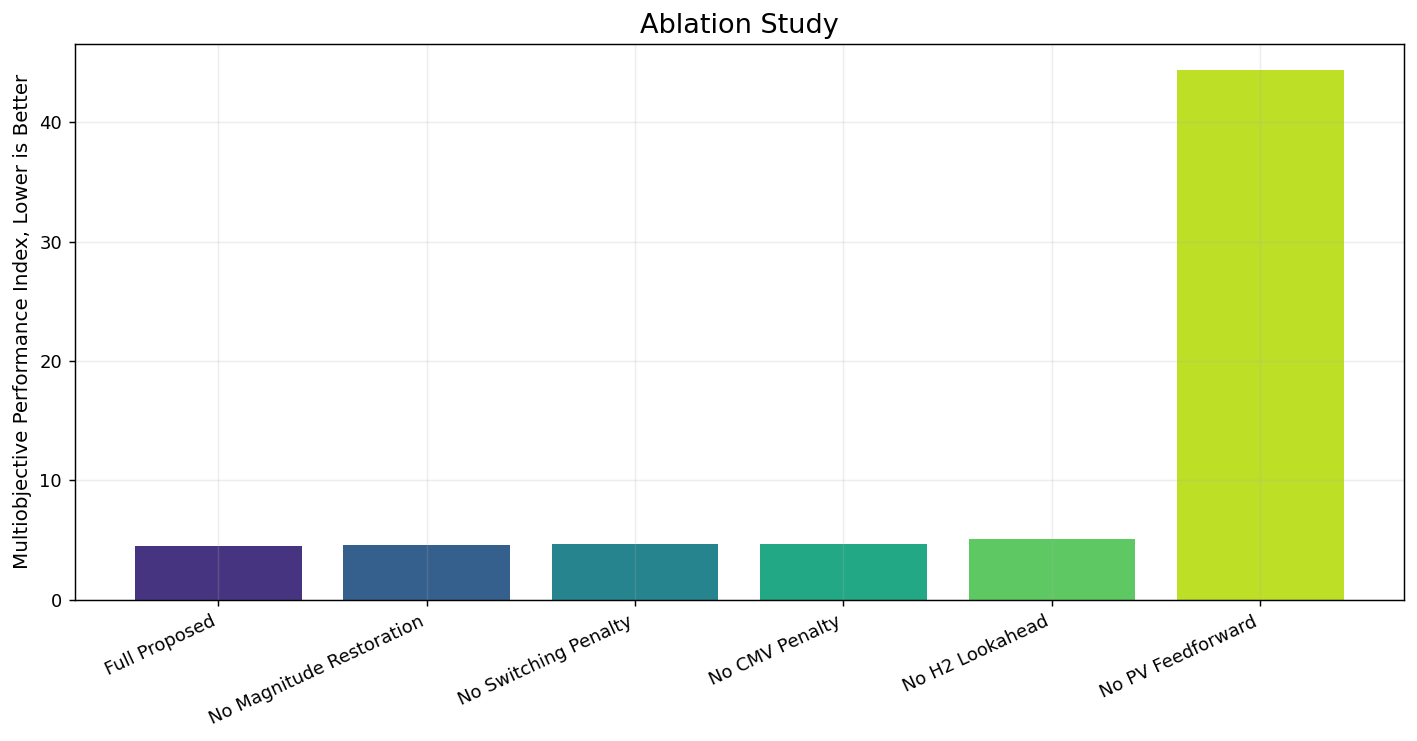

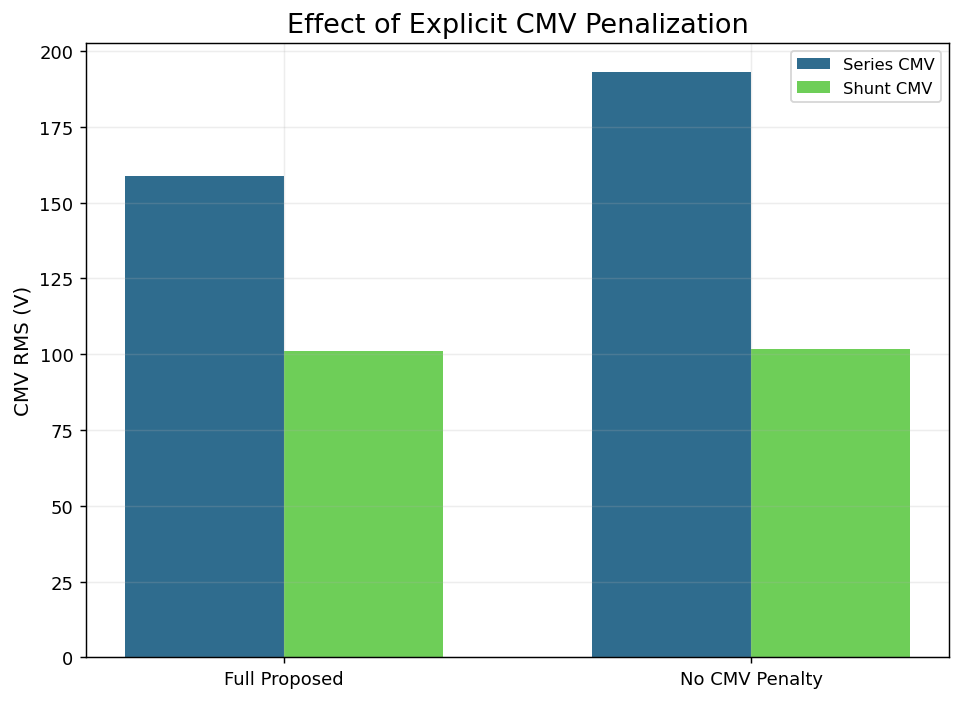

In [ ]:

def run_series_proposed_h1(
    vs,
    vr,
    fs=None,
    ratio=SERIES_RATIO,
    L=SERIES_L,
    C=SERIES_C,
    R=SERIES_R,
    lambda_sw=SERIES_LAMBDA_SW,
    lambda_cm=SERIES_LAMBDA_CMV,
    amp_k=SERIES_AMP_K,
    amp_tau=SERIES_AMP_TAU,
):
    if fs is None:
        fs = FS_SIM

    dt = 1 / fs
    n = len(vs)

    vc = np.zeros((n, 3))
    i_f = np.zeros((n, 3))
    idx = np.zeros(n, dtype=int)

    prev_idx = 0

    bypass_mask = clean_grid_deadband_mask(
        vs,
        vr,
        fs=fs,
    )

    amp_est = np.ones(3) * V_PHASE_PEAK
    amp_alpha = np.exp(-dt / amp_tau)

    for k in range(1, n):
        if bypass_mask[k]:
            vc[k] = 0.0
            i_f[k] = 0.0
            idx[k] = BYPASS_STATE_IDX
            prev_idx = BYPASS_STATE_IDX
            amp_est[:] = V_PHASE_PEAK
            continue

        unit_prev = vr[k - 1] / V_PHASE_PEAK
        vload_prev = vs[k - 1] + vc[k - 1]

        amp_inst = 2 * vload_prev * unit_prev

        amp_est = (
            amp_alpha * amp_est
            + (1 - amp_alpha) * amp_inst
        )

        amp_correction = np.clip(
            amp_k * (V_PHASE_PEAK - amp_est),
            -0.08 * V_PHASE_PEAK,
            0.08 * V_PHASE_PEAK
        )

        ref1 = (
            vr[k]
            + amp_correction
            * (vr[k] / V_PHASE_PEAK)
        )

        vm1, cm1 = matrix_candidates(
            vs[k],
            ratio
        )

        i1 = (
            i_f[k - 1]
            + dt / L
            * (
                vm1
                - vc[k - 1]
                - R * i_f[k - 1]
            )
        )

        v1 = (
            vc[k - 1]
            + dt / C * i1
        )

        err1 = (
            vs[k]
            + v1
            - ref1
        ) / V_PHASE_PEAK

        track1 = np.mean(
            err1 ** 2,
            axis=1
        )

        gate1 = np.exp(
            -track1 / 0.002
        )

        cost1 = (
            track1
            + gate1
            * lambda_sw
            * STATE_DISTANCE[prev_idx]
            + gate1
            * lambda_cm
            * (cm1 / V_PHASE_PEAK) ** 2
        )

        j = int(np.argmin(cost1))

        i_f[k] = i1[j]
        vc[k] = v1[j]
        idx[k] = j
        prev_idx = j

    return (
        vs + vc,
        vc,
        i_f,
        idx
    )


def run_shunt_proposed_h1(
    vpcc,
    iref,
    fs=None,
    ratio=SHUNT_RATIO,
    L=SHUNT_L,
    R=SHUNT_R,
    lambda_sw=SHUNT_LAMBDA_SW,
    lambda_cm=SHUNT_LAMBDA_CMV,
):
    if fs is None:
        fs = FS_SIM

    dt = 1 / fs
    n = len(vpcc)

    ic = np.zeros((n, 3))
    idx = np.zeros(n, dtype=int)

    prev_idx = 0

    for k in range(1, n):
        vm1, cm1 = matrix_candidates(
            vpcc[k],
            ratio
        )

        i1 = (
            ic[k - 1]
            + dt / L
            * (
                vm1
                - vpcc[k]
                - R * ic[k - 1]
            )
        )

        err1 = (
            i1
            - iref[k]
        ) / 30.0

        track1 = np.mean(
            err1 ** 2,
            axis=1
        )

        gate1 = np.exp(
            -track1 / 0.004
        )

        cost1 = (
            track1
            + gate1
            * lambda_sw
            * STATE_DISTANCE[prev_idx]
            + gate1
            * lambda_cm
            * (cm1 / V_PHASE_PEAK) ** 2
        )

        j = int(np.argmin(cost1))

        ic[k] = i1[j]
        idx[k] = j
        prev_idx = j

    return ic, idx


def evaluate_ablation(
    variant
):
    if variant == "Full Proposed":

        vl, _, _, sidx = run_series_proposed(
            v_source,
            v_reference
        )

        series_sw = SERIES_LAMBDA_SW
        series_cm = SERIES_LAMBDA_CMV
        amp_k = SERIES_AMP_K

        shunt_sw = SHUNT_LAMBDA_SW
        shunt_cm = SHUNT_LAMBDA_CMV
        use_h2 = True
        use_pv_ff = True

    elif variant == "No H2 Lookahead":

        vl, _, _, sidx = run_series_proposed_h1(
            v_source,
            v_reference
        )

        series_sw = SERIES_LAMBDA_SW
        series_cm = SERIES_LAMBDA_CMV
        amp_k = SERIES_AMP_K

        shunt_sw = SHUNT_LAMBDA_SW
        shunt_cm = SHUNT_LAMBDA_CMV
        use_h2 = "proposed_h1"
        use_pv_ff = True

    elif variant == "No Switching Penalty":

        vl, _, _, sidx = run_series_proposed(
            v_source,
            v_reference,
            lambda_sw=0.0
        )

        series_sw = 0.0
        series_cm = SERIES_LAMBDA_CMV
        amp_k = SERIES_AMP_K

        shunt_sw = 0.0
        shunt_cm = SHUNT_LAMBDA_CMV
        use_h2 = True
        use_pv_ff = True

    elif variant == "No CMV Penalty":

        vl, _, _, sidx = run_series_proposed(
            v_source,
            v_reference,
            lambda_cm=0.0
        )

        series_sw = SERIES_LAMBDA_SW
        series_cm = 0.0
        amp_k = SERIES_AMP_K

        shunt_sw = SHUNT_LAMBDA_SW
        shunt_cm = 0.0
        use_h2 = True
        use_pv_ff = True

    elif variant == "No Magnitude Restoration":

        vl, _, _, sidx = run_series_proposed(
            v_source,
            v_reference,
            amp_k=0.0
        )

        series_sw = SERIES_LAMBDA_SW
        series_cm = SERIES_LAMBDA_CMV
        amp_k = 0.0

        shunt_sw = SHUNT_LAMBDA_SW
        shunt_cm = SHUNT_LAMBDA_CMV
        use_h2 = True
        use_pv_ff = True

    elif variant == "No PV Feedforward":

        vl, _, _, sidx = run_series_proposed(
            v_source,
            v_reference
        )

        series_sw = SERIES_LAMBDA_SW
        series_cm = SERIES_LAMBDA_CMV
        amp_k = SERIES_AMP_K

        shunt_sw = SHUNT_LAMBDA_SW
        shunt_cm = SHUNT_LAMBDA_CMV
        use_h2 = True
        use_pv_ff = False

    else:
        raise ValueError(variant)

    unit = (
        v_reference
        / V_PHASE_PEAK
    )

    ipv = (
        (
            pv_power
            / (
                1.5
                * V_PHASE_PEAK
            )
        )[:, None]
        * unit
    )

    pinst = np.sum(
        vl * i_load,
        axis=1
    )

    pavg = lowpass(
        pinst,
        tau=0.020,
        initial=np.mean(
            pinst[:SPC]
        )
    )

    pgrid = (
        pavg
        - pv_power
    )

    igr = (
        (
            pgrid
            / (
                1.5
                * V_PHASE_PEAK
            )
        )[:, None]
        * unit
    )

    if use_pv_ff:
        ipv_reference = ipv
    else:
        ipv_reference = 0.0

    icref = (
        i_load
        - ipv_reference
        - igr
    )

    if use_h2 is True:

        ic, qidx = run_shunt_proposed(
            vl,
            icref,
            lambda_sw=shunt_sw,
            lambda_cm=shunt_cm
        )

    elif use_h2 == "proposed_h1":

        ic, qidx = run_shunt_proposed_h1(
            vl,
            icref,
            lambda_sw=shunt_sw,
            lambda_cm=shunt_cm
        )

    else:

        ic, qidx = run_shunt_fcs_h1(
            vl,
            icref
        )

    ig = (
        i_load
        - ipv
        - ic
    )

    sl = slice(
        SPC,
        None
    )

    vthd = mean_3ph_thd(
        vl[sl]
    )

    ithd = mean_3ph_thd(
        ig[sl]
    )

    re = np.mean([
        abs(
            rms(vl[sl, p])
            - V_PHASE_RMS
        )
        / V_PHASE_RMS
        * 100

        for p in range(3)
    ])

    pf = pf_3ph(
        vl[sl],
        ig[sl]
    )

    series_event = switching_state_transition_rate_khz(
        sidx
    )

    shunt_event = switching_state_transition_rate_khz(
        qidx
    )

    series_cmv = common_mode_rms(
        v_source,
        sidx
    )

    shunt_cmv = common_mode_rms(
        vl,
        qidx
    )

    pqi = (
        vthd
        + ithd
        + re
        + 50 * (1 - pf)
    )

    multi_index = (
        pqi

        + 0.014
        * (
            series_event
            + shunt_event
        )

        + 0.001
        * (
            series_cmv
            + shunt_cmv
        )
    )

    return {
        "Variant": variant,
        "V_THD_pct": vthd,
        "I_THD_pct": ithd,
        "RMS_Error_pct": re,
        "PF": pf,
        "PQI": pqi,
        "Multiobjective_Index": multi_index,
        "Switching_State_Transition_Rate_kHz":
            np.mean([
                series_event,
                shunt_event
            ]),
        "Series_CMV_RMS_V":
            series_cmv,
        "Shunt_CMV_RMS_V":
            shunt_cmv,
    }


ABLATION_VARIANTS = [
    "Full Proposed",
    "No H2 Lookahead",
    "No Switching Penalty",
    "No CMV Penalty",
    "No Magnitude Restoration",
    "No PV Feedforward",
]

ablation_rows = []

for variant in ABLATION_VARIANTS:
    ablation_rows.append(
        evaluate_ablation(
            variant
        )
    )

ablation_summary = pd.DataFrame(
    ablation_rows
)

display(
    ablation_summary.round(4)
)

plot_df = ablation_summary.sort_values(
    "Multiobjective_Index"
)

colors = VIRIDIS(
    np.linspace(
        0.15,
        0.90,
        len(plot_df)
    )
)

plt.figure(figsize=(11, 5.8))

plt.bar(
    plot_df["Variant"],
    plot_df["Multiobjective_Index"],
    color=colors
)

plt.ylabel("Multiobjective Performance Index, Lower is Better")
plt.title("Ablation Study")
plt.xticks(
    rotation=25,
    ha="right"
)
finish_plot("stage19_ablation.png")

cmv_df = ablation_summary[
    ablation_summary["Variant"].isin([
        "Full Proposed",
        "No CMV Penalty"
    ])
]

plt.figure(figsize=(7.5, 5.5))

x = np.arange(
    len(cmv_df)
)

w = 0.34

plt.bar(
    x - w / 2,
    cmv_df["Series_CMV_RMS_V"],
    w,
    color=VIRIDIS(0.35),
    label="Series CMV"
)

plt.bar(
    x + w / 2,
    cmv_df["Shunt_CMV_RMS_V"],
    w,
    color=VIRIDIS(0.78),
    label="Shunt CMV"
)

plt.xticks(
    x,
    cmv_df["Variant"]
)

plt.ylabel("CMV RMS (V)")
plt.title("Effect of Explicit CMV Penalization")
plt.legend()
finish_plot("stage19_cmv_ablation.png")

## Stage 20 — Robustness Across All 17 SEED-PQD Classes and Energy-Limited Interruption Case

,Class,V_THD_Before_pct,V_THD_After_pct,RMS_Error_Before_pct,RMS_Error_After_pct,Switching_State_Transition_Rate_kHz,THD_Reduction_pct,Operating_Interpretation
0,Pure_Sinusoidal,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,Normal compensation operating case
1,Sag,14.8462,1.5541,11.9490,0.4144,15.2941,89.5321,Normal compensation operating case
2,Swell,12.8268,0.7957,40.5201,0.0346,16.7960,93.7968,Normal compensation operating case
3,Interruption,189.7682,113.8972,78.9946,59.5078,3.7297,39.9809,Energy-limited without battery/supercapacitor ...
4,Transient,2.0084,0.5549,0.3039,0.1193,7.7597,72.3725,Normal compensation operating case
5,Oscillatory_Transient,10.3276,0.3963,0.1263,0.1297,12.2904,96.1630,Normal compensation operating case
6,Harmonics,19.4104,1.2096,1.8664,0.5793,15.8698,93.7681,Normal compensation operating case
7,Harmonics_with_Sag,44.6112,26.3583,22.8991,8.1749,13.1915,40.9154,Normal compensation operating case
8,Harmonics_with_Swell,19.0078,1.9563,54.2053,0.1769,17.3967,89.7079,Normal compensation operating case
9,Flicker,2.3611,0.4971,4.4591,0.0661,14.6183,78.9445,Normal compensation operating case


Interruption interpretation: a direct matrix-converter UPQC has no large DC energy buffer. During complete source interruption, full voltage ride-through is energy-limited unless PV energy is buffered by a battery or supercapacitor. The interruption result is reported as a physical energy-availability limitation, not hidden as a controller failure.


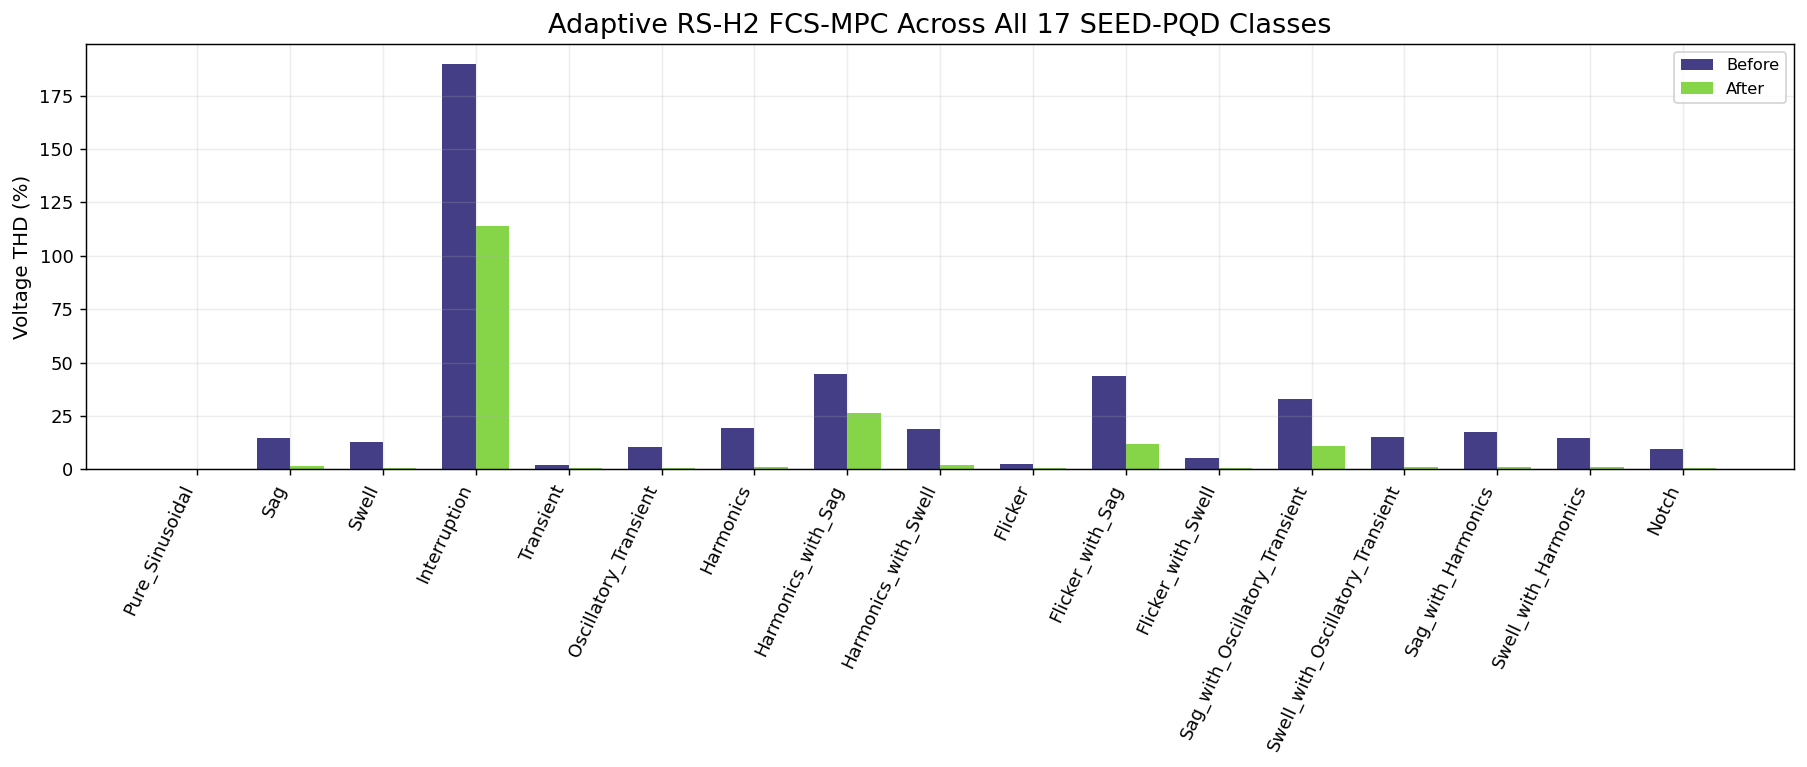

In [ ]:
class_rows = []

for cls in CLASS_ORDER:

    x = align_fundamental(
        pq_data[cls][0]
    )

    cyc = three_phase_positive_sequence(x)

    vs = np.tile(
        cyc,
        (2, 1)
    )

    theta, _ = robust_positive_sequence_sync(vs)

    vr = make_vref(theta)

    vl, _, _, idx = run_series_proposed(
        vs,
        vr
    )

    sl = slice(
        SPC,
        None
    )

    before_thd = mean_3ph_thd(
        vs[sl]
    )

    after_thd = mean_3ph_thd(
        vl[sl]
    )

    before_rms_error = np.mean([
        abs(
            rms(vs[sl, p])
            - V_PHASE_RMS
        )
        / V_PHASE_RMS
        * 100

        for p in range(3)
    ])

    after_rms_error = np.mean([
        abs(
            rms(vl[sl, p])
            - V_PHASE_RMS
        )
        / V_PHASE_RMS
        * 100

        for p in range(3)
    ])

    class_rows.append({
        "Class": cls,
        "V_THD_Before_pct":
            before_thd,
        "V_THD_After_pct":
            after_thd,
        "RMS_Error_Before_pct":
            before_rms_error,
        "RMS_Error_After_pct":
            after_rms_error,
        "Switching_State_Transition_Rate_kHz":
            switching_state_transition_rate_khz(idx),
    })

classwise = pd.DataFrame(
    class_rows
)

before_thd = classwise["V_THD_Before_pct"].to_numpy()
after_thd = classwise["V_THD_After_pct"].to_numpy()

classwise["THD_Reduction_pct"] = np.where(
    before_thd > 1e-6,
    100 * (before_thd - after_thd) / before_thd,
    0.0
)

classwise["Operating_Interpretation"] = np.where(
    classwise["Class"].eq("Interruption"),
    "Energy-limited without battery/supercapacitor storage",
    "Normal compensation operating case",
)

display(
    classwise.round(4)
)

print(
    "Interruption interpretation: a direct matrix-converter UPQC has no large "
    "DC energy buffer. During complete source interruption, full voltage "
    "ride-through is energy-limited unless PV energy is buffered by a battery "
    "or supercapacitor. The interruption result is reported as a physical "
    "energy-availability limitation, not hidden as a controller failure."
)

x = np.arange(
    len(classwise)
)

w = 0.36

colors = VIRIDIS([0.18, 0.82])

plt.figure(figsize=(14, 6))

plt.bar(
    x - w / 2,
    classwise["V_THD_Before_pct"],
    w,
    color=colors[0],
    label="Before"
)

plt.bar(
    x + w / 2,
    classwise["V_THD_After_pct"],
    w,
    color=colors[1],
    label="After"
)

plt.xticks(
    x,
    classwise["Class"],
    rotation=65,
    ha="right"
)

plt.ylabel("Voltage THD (%)")
plt.title("Adaptive RS-H2 FCS-MPC Across All 17 SEED-PQD Classes")
plt.legend()
finish_plot("stage20_all_17_classes.png")

## Stage 21 — Parameter-Mismatch Robustness

,L_Mismatch_pct,V_THD_pct,RMS_Error_pct,Switching_State_Transition_Rate_kHz
0,-20.0,1.1618,0.3495,17.6814
1,-10.0,1.1591,0.3537,17.2310
2,0.0,1.1337,0.3599,17.2477
3,10.0,1.1078,0.3672,17.1309
4,20.0,1.2195,0.3647,16.8307


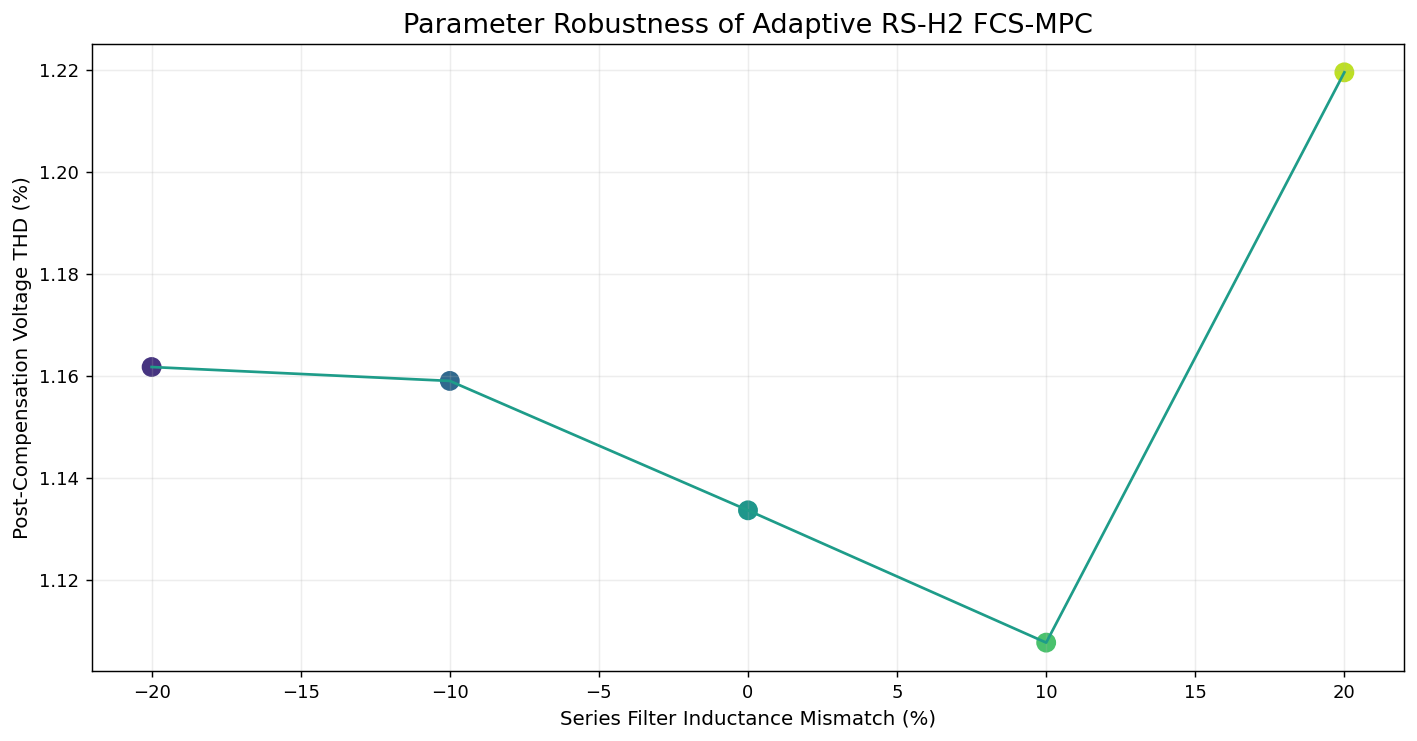

In [ ]:
uncertainty_cases = [
    -0.20,
    -0.10,
    0.0,
    0.10,
    0.20,
]

x = align_fundamental(
    pq_data[
        "Sag_with_Harmonics"
    ][0]
)

cyc = three_phase_positive_sequence(x)

vs_u = np.tile(
    cyc,
    (3, 1)
)

theta_u, _ = robust_positive_sequence_sync(
    vs_u
)

vr_u = make_vref(
    theta_u
)

uncertainty_rows = []

for delta in uncertainty_cases:

    L_model = (
        SERIES_L
        * (1 + delta)
    )

    vl, _, _, idx = run_series_proposed(
        vs_u,
        vr_u,
        L=L_model
    )

    sl = slice(
        SPC,
        None
    )

    uncertainty_rows.append({
        "L_Mismatch_pct":
            100 * delta,

        "V_THD_pct":
            mean_3ph_thd(
                vl[sl]
            ),

        "RMS_Error_pct":
            np.mean([
                abs(
                    rms(vl[sl, p])
                    - V_PHASE_RMS
                )
                / V_PHASE_RMS
                * 100

                for p in range(3)
            ]),

        "Switching_State_Transition_Rate_kHz":
            switching_state_transition_rate_khz(
                idx
            ),
    })

uncertainty = pd.DataFrame(
    uncertainty_rows
)

display(
    uncertainty.round(4)
)

colors = VIRIDIS(
    np.linspace(
        0.15,
        0.90,
        len(uncertainty)
    )
)

plt.figure()

plt.scatter(
    uncertainty["L_Mismatch_pct"],
    uncertainty["V_THD_pct"],
    s=100,
    c=colors
)

plt.plot(
    uncertainty["L_Mismatch_pct"],
    uncertainty["V_THD_pct"],
    color=VIRIDIS(0.55),
    lw=1.5
)

plt.xlabel("Series Filter Inductance Mismatch (%)")
plt.ylabel("Post-Compensation Voltage THD (%)")
plt.title("Parameter Robustness of Adaptive RS-H2 FCS-MPC")
finish_plot("stage21_parameter_robustness.png")

## Stage 22 — Separate Recent Published Literature Context

The following table is **cross-testbed literature context only**. Published studies use different ratings, converter topologies, disturbances, datasets, hardware, and validation settings. These values are not included in the controlled baseline statistics or used to claim universal numerical superiority.

,Year,Study,Controller,Topology,Validation,Reported_Result,DOI
0,2026,Yu et al.,FCS-MPC + LADRC-MSTOGI-PLL,UPQC,MATLAB/Simulink simulation,85% voltage-sag compensation within 12.5 ms,10.3934/electreng.2026018
1,2026,Sravanthi et al.,Fuzzy Logic Sliding Mode Controller,Solar-PV-fed UPQC,MATLAB/Simulink simulation,Source voltage THD 0.38%; source current THD 2...,10.1038/s41598-026-43465-0
2,2025,Wang et al.,Model-Free Predictive Direct Control,UPQC,Simulation + Typhoon HIL 402,Grid-current THD <2% with 50% parameter mismatch,10.1049/esi2.70009
3,2025,Chen et al.,CCS-MPC + PSC-PWM,MMC-UPQC,MATLAB/Simulink simulation,1.44% load-voltage THD under harmonic injectio...,10.3390/en18112946
4,2024,Trivedi et al.,Sliding-Mode Direct Power Control,20-kVA UPQC,MATLAB/Simulink simulation,Source-current THD 1.52%,10.1016/j.heliyon.2024.e39597
5,2024,Jiang and Zhang,Reduced-Finite-Set Multistep MPC,MMC-UPQC,Simulation + RT-LAB HIL,Reduced finite set with multistep prediction; ...,10.1016/j.conengprac.2023.105773
6,2024,Wang et al.,Predictive Direct Control + PAC + FCS-MPC,UPQC,Simulation + laboratory prototype,Predictive direct control validated by simulat...,10.1016/j.ijepes.2023.109718


,Method,V_THD_pct,I_THD_pct,RMS_Error_pct,PF,PQI,Multiobjective_Index,Switching_State_Transition_Rate_kHz,Series_CMV_RMS_V,Shunt_CMV_RMS_V,Runtime_s
3,Proposed-Adaptive-RS-H2-FCS,0.5259,0.7626,0.1093,0.9514,3.8254,4.5221,15.603,158.848,100.9867,4.9746


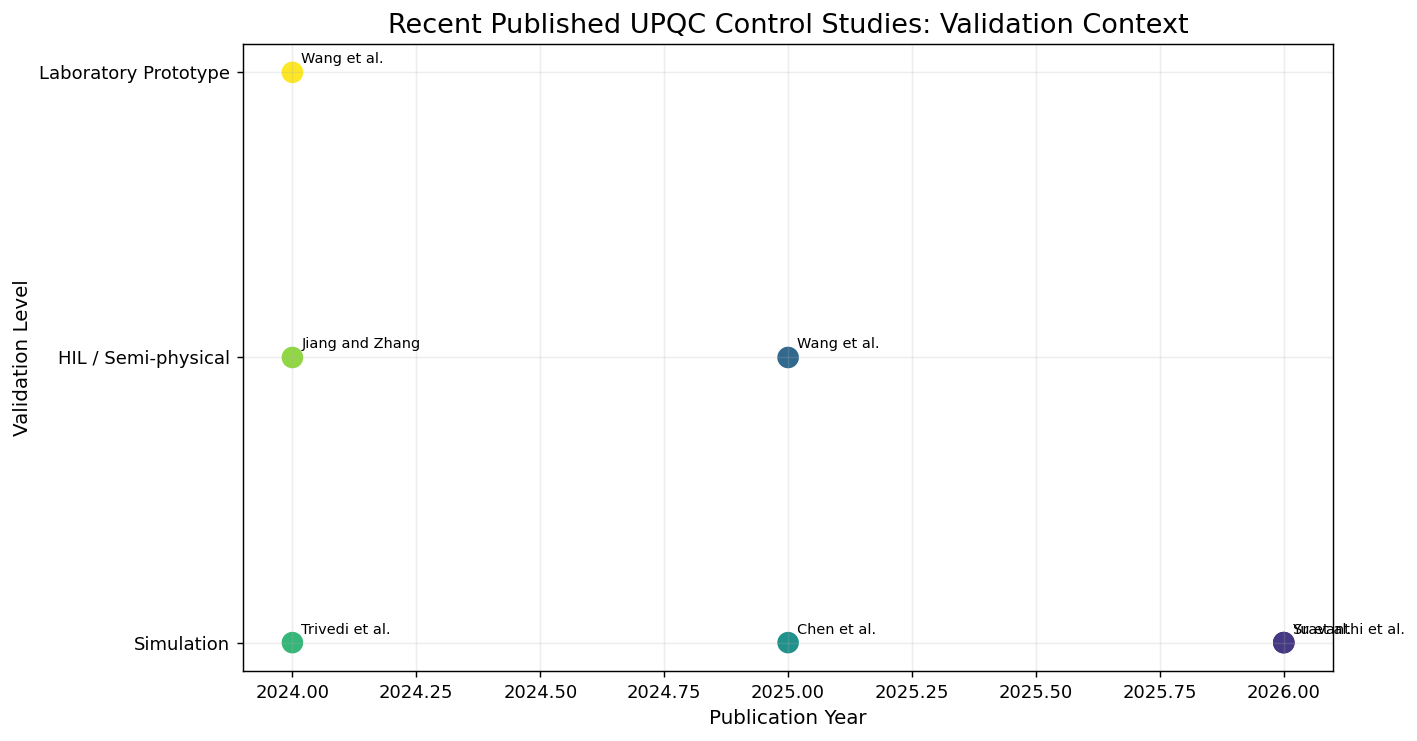

In [ ]:

published_literature_context = pd.DataFrame([
    {
        "Year": 2026,
        "Study": "Yu et al.",
        "Controller": "FCS-MPC + LADRC-MSTOGI-PLL",
        "Topology": "UPQC",
        "Validation": "MATLAB/Simulink simulation",
        "Reported_Result": "85% voltage-sag compensation within 12.5 ms",
        "DOI": "10.3934/electreng.2026018",
    },
    {
        "Year": 2026,
        "Study": "Sravanthi et al.",
        "Controller": "Fuzzy Logic Sliding Mode Controller",
        "Topology": "Solar-PV-fed UPQC",
        "Validation": "MATLAB/Simulink simulation",
        "Reported_Result": "Source voltage THD 0.38%; source current THD 2.01%",
        "DOI": "10.1038/s41598-026-43465-0",
    },
    {
        "Year": 2025,
        "Study": "Wang et al.",
        "Controller": "Model-Free Predictive Direct Control",
        "Topology": "UPQC",
        "Validation": "Simulation + Typhoon HIL 402",
        "Reported_Result": "Grid-current THD <2% with 50% parameter mismatch",
        "DOI": "10.1049/esi2.70009",
    },
    {
        "Year": 2025,
        "Study": "Chen et al.",
        "Controller": "CCS-MPC + PSC-PWM",
        "Topology": "MMC-UPQC",
        "Validation": "MATLAB/Simulink simulation",
        "Reported_Result": "1.44% load-voltage THD under harmonic injection; 1.34% grid-current THD in composite test",
        "DOI": "10.3390/en18112946",
    },
    {
        "Year": 2024,
        "Study": "Trivedi et al.",
        "Controller": "Sliding-Mode Direct Power Control",
        "Topology": "20-kVA UPQC",
        "Validation": "MATLAB/Simulink simulation",
        "Reported_Result": "Source-current THD 1.52%",
        "DOI": "10.1016/j.heliyon.2024.e39597",
    },
    {
        "Year": 2024,
        "Study": "Jiang and Zhang",
        "Controller": "Reduced-Finite-Set Multistep MPC",
        "Topology": "MMC-UPQC",
        "Validation": "Simulation + RT-LAB HIL",
        "Reported_Result": "Reduced finite set with multistep prediction; series and shunt validation",
        "DOI": "10.1016/j.conengprac.2023.105773",
    },
    {
        "Year": 2024,
        "Study": "Wang et al.",
        "Controller": "Predictive Direct Control + PAC + FCS-MPC",
        "Topology": "UPQC",
        "Validation": "Simulation + laboratory prototype",
        "Reported_Result": "Predictive direct control validated by simulation and laboratory prototype",
        "DOI": "10.1016/j.ijepes.2023.109718",
    },
])

display(published_literature_context)

# Same-platform proposed results are deliberately shown separately.
proposed_same_platform_summary = comparison[
    comparison["Method"].eq("Proposed-Adaptive-RS-H2-FCS")
][[
    "Method",
    "V_THD_pct",
    "I_THD_pct",
    "RMS_Error_pct",
    "PF",
    "PQI",
    "Multiobjective_Index",
    "Switching_State_Transition_Rate_kHz",
    "Series_CMV_RMS_V",
    "Shunt_CMV_RMS_V",
    "Runtime_s",
]].copy()

display(proposed_same_platform_summary.round(4))

# Publication-year / validation-context visualization only.
validation_map = {
    "MATLAB/Simulink simulation": 1,
    "Simulation + Typhoon HIL 402": 2,
    "Simulation + RT-LAB HIL": 2,
    "Simulation + laboratory prototype": 3,
}

plot_lit = published_literature_context.copy()
plot_lit["Validation_Level"] = plot_lit["Validation"].map(validation_map)

plt.figure(figsize=(11, 5.8))
plt.scatter(
    plot_lit["Year"],
    plot_lit["Validation_Level"],
    s=120,
    c=np.linspace(0.15, 0.9, len(plot_lit)),
    cmap="viridis",
)
for _, row in plot_lit.iterrows():
    plt.annotate(
        row["Study"],
        (row["Year"], row["Validation_Level"]),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=8,
    )

plt.yticks(
    [1, 2, 3],
    ["Simulation", "HIL / Semi-physical", "Laboratory Prototype"],
)
plt.xlabel("Publication Year")
plt.ylabel("Validation Level")
plt.title("Recent Published UPQC Control Studies: Validation Context")
finish_plot("stage22_literature_validation_context.png")


## Stage 23 — Final Same-Platform Multiobjective Summary

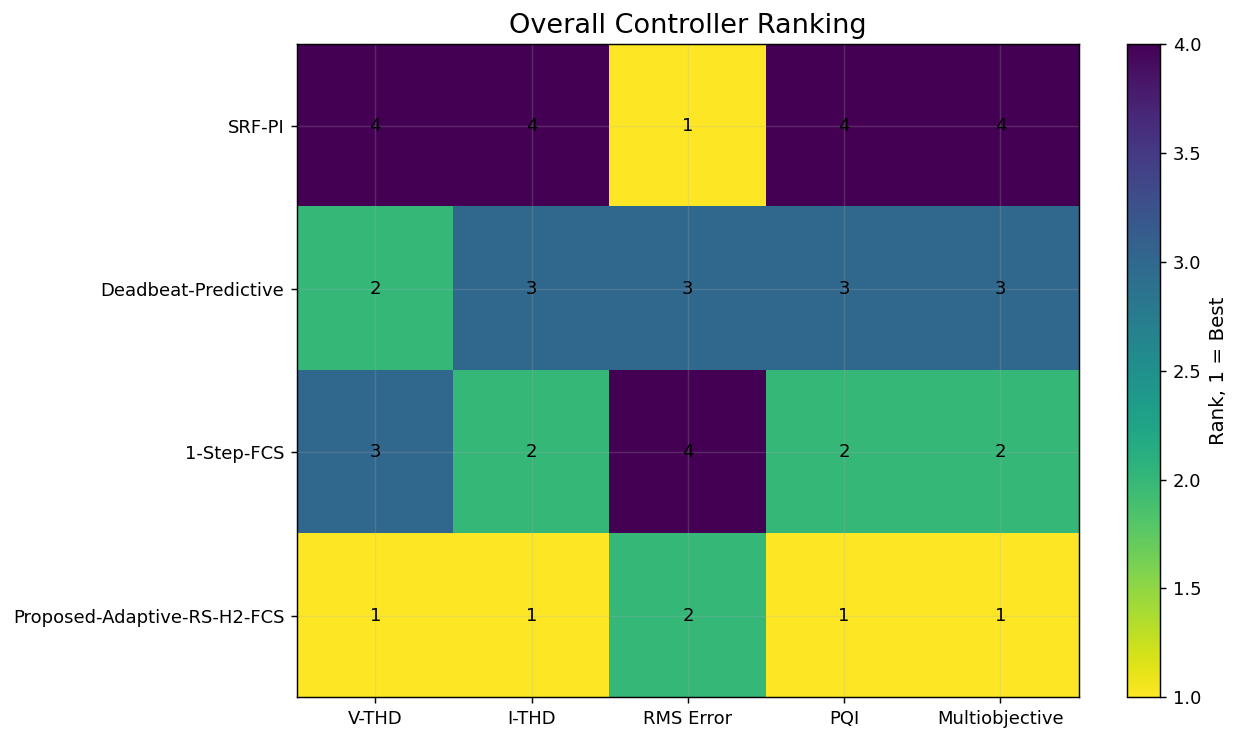

In [ ]:
summary_methods = comparison.copy()

score_cols = [
    "V_THD_pct",
    "I_THD_pct",
    "RMS_Error_pct",
    "PQI",
    "Multiobjective_Index",
]

rank_matrix = np.zeros(
    (
        len(summary_methods),
        len(score_cols)
    )
)

for j, col in enumerate(score_cols):

    vals = summary_methods[
        col
    ].to_numpy()

    order = np.argsort(vals)

    ranks = np.empty_like(
        order,
        dtype=float
    )

    ranks[order] = np.arange(
        1,
        len(vals) + 1
    )

    rank_matrix[:, j] = ranks

plt.figure(figsize=(10, 5.8))

img = plt.imshow(
    rank_matrix,
    cmap="viridis_r",
    aspect="auto",
    vmin=1,
    vmax=len(summary_methods)
)

plt.colorbar(
    img,
    label="Rank, 1 = Best"
)

plt.xticks(
    np.arange(len(score_cols)),
    [
        "V-THD",
        "I-THD",
        "RMS Error",
        "PQI",
        "Multiobjective",
    ]
)

plt.yticks(
    np.arange(len(summary_methods)),
    summary_methods["Method"]
)

for r in range(
    rank_matrix.shape[0]
):
    for c in range(
        rank_matrix.shape[1]
    ):
        plt.text(
            c,
            r,
            f"{int(rank_matrix[r, c])}",
            ha="center",
            va="center"
        )

plt.title("Overall Controller Ranking")
finish_plot("stage23_overall_ranking.png")